# Separating temperature from supply with two ring oscillators in GF180MCU

**Author:** Orlando Arturo Palma León, Universidad de Sonora (México)
**Submission:** IEEE SSCS Code-a-Chip, ISSCC 2027
**License:** Apache License 2.0 (see `LICENSE`)
**Tools:** ngspice 45.2, GF180MCU open PDK (`gf180mcu_fd_pr` models, open_pdks `gf180mcuC`), magic 8.3.464, netgen 1.5.272, schemdraw 0.23

**Abstract.** A ring oscillator is the simplest on-chip temperature sensor, but its frequency depends just as much
on the supply voltage. This notebook designs, characterizes and lays out, in the open GF180MCU PDK with ngspice,
magic and netgen, a monitor that combines two 11-stage rings to separate temperature from supply, and studies how
mismatch, layout parasitics and aging affect it. Ring A is a plain CMOS ring; ring B is a current-starved ring whose current comes from a poly resistor
and a pMOS-over-nMOS diode stack. Across five process corners, −40 to 125 °C and a ±10 % supply, ring A alone with a
one-point calibration reads temperature within about 1.5 °C at nominal supply, but errs by 45 to 63 °C once the
supply moves, because near room temperature 10 mV look like 1.1–1.4 °C. The choice of ring B's bias stack flips the
sign of its supply sensitivity (condition number from 33 to 2.1) and makes it robust to the fs and sf corners. With
one calibration temperature plus a supply trim that needs no temperature chamber, the two-ring read-out stays within
about 2 °C in four corners and 5 °C in ff, with a residual supply sensitivity of about 3.5 °C/V or less. A mismatch
Monte Carlo then shows the real limit: the current-mirror reference shared by all stages of ring B spreads its
temperature coefficient by 12 % and the read-out by ±8 °C (3σ). Making that reference 16 times larger, verified by a
second Monte Carlo, cuts the spread to ±2.4 °C; alternatively, since the same offset shifts ring B's calibration
frequency, that frequency predicts the error (correlation −0.98) and a one-coefficient correction also reaches
±2.4 °C, provided process and mismatch can be told apart. Both rings are laid out as code, DRC- and LVS-clean in
about 0.0019 mm²; the extracted parasitics slow them by 27–29 % without changing ring A's temperature coefficient, but
lower ring B's by 7 %, so the read-out has to be fitted on extracted netlists. Aging moves the two rings in opposite directions, so
10 mV of NBTI reads as about 3 °C, which motivates a third, unstressed reference ring. Every number is reproducible
from a clean Colab runtime, with a numerical precision of about ±0.3 °C.

**Results at a glance** (values from the run saved with this notebook; a new run can differ by about 0.2 °C)

| | Ring A alone | Rings A + B with supply trim |
|---|---|---|
| Inaccuracy, 5 corners, ±10 % supply (one-point calibration) | 45–63 °C | ≤ 2 °C in four corners, 4.9 °C in ff |
| Residual supply sensitivity | 126–166 °C/V | ≤ 3.5 °C/V |
| Mismatch, 16 Monte Carlo chips (3σ) | 0.3 °C | 8.0 °C; 2.4 °C with a 16× larger mirror reference |
| Layout parasitics, schematic read-out | 1.1 °C | 3.0 °C |
| Aging, 10 mV of NBTI | 1.0 °C | 3.1 °C |
| Area (DRC- and LVS-clean layout) | 202 µm² | 202 + 1660 µm² |
| Power, continuous | 1.2 mW | 1.4 mW |

**Flow:** schematic (ngspice) → PVT corners → two-ring read-out → mismatch Monte Carlo → diagnosis and fix → layout
written as code (magic), DRC and LVS (netgen) → post-layout simulation → aging → error budget (section 12).

**Key findings**

1. The bias stack of ring B decides whether temperature and supply can be separated at all (condition number 33 with
   one diode, 2.1 with a pMOS over an nMOS diode).
2. Mismatch, not process, limits the two-ring read-out, and one device carries most of it: MNB, the mirror reference
   shared by all stages. Enlarging it and MNM cuts the spread from ±8 to ±2.4 °C (3σ).
3. The calibration frequency that every chip measures anyway predicts that mismatch error (correlation −0.98), a
   correction that costs no hardware once process and mismatch can be told apart.
4. Layout parasitics slow both rings by about 28 % without changing ring A's TC, but change ring B's by 7 %: the
   read-out has to be fitted on extracted netlists.

Everything in this notebook runs from a clean Google Colab runtime: the first cell builds ngspice and
fetches the device models at pinned versions, so every number below can be reproduced. The PVT grids and the Monte
Carlo runs are cached as CSV files, so re-running cells in the same session only reloads them.

## 1. Environment

Builds ngspice 45.2 from source and downloads the GF180MCU ngspice models at a
fixed commit. The ngspice package of Colab's Ubuntu is several releases older than the one these results were
obtained with, so the cell builds the tested release instead. Re-running the cell skips whatever is already in
place. To use your own installation, set the
environment variables `NGSPICE` and `GF180_MODELS` before running it.

In [1]:
import os, shutil, subprocess

WORK = os.path.abspath("gf180_work")
os.makedirs(WORK, exist_ok=True)
NGSPICE_TAG = "ngspice-45.2"                                  # tested version
GF180_REPO = "https://github.com/fossi-foundation/globalfoundries-pdk-libs-gf180mcu_fd_pr.git"
GF180_COMMIT = "5e4be8726e2ae8be099c4131f697a353d6457874"     # tested commit (2026-10-19)


import time

LOG = os.path.join(WORK, "setup.log")


def sh(label, cmd, cwd=None):
    # Runs a shell step, keeps its output in setup.log and shows it only if the step fails
    # (Colab does not display the output of child processes in the cell).
    print(f"{label} ...", flush=True)
    with open(LOG, "a") as log:
        log.write(f"\n$ {cmd}\n")
        log.flush()
        p = subprocess.run(cmd, shell=True, cwd=cwd, stdout=log, stderr=subprocess.STDOUT)
    if p.returncode != 0:
        with open(LOG) as log:
            tail = log.read().splitlines()[-40:]
        print("\n".join(tail))
        raise RuntimeError(f"Step failed: {label} (exit {p.returncode}). Last lines of {LOG} above.")


# ngspice ---------------------------------------------------------------------
NGSPICE = os.environ.get("NGSPICE", os.path.join(WORK, "local", "bin", "ngspice"))
if not os.path.exists(NGSPICE):
    tools = ["git", "gcc", "make", "bison", "flex", "autoconf", "automake", "libtoolize"]
    if any(shutil.which(t) is None for t in tools):
        sh("installing build tools (apt)",
           "apt-get -qq update && apt-get -qq install -y build-essential bison flex autoconf automake libtool")
    src = os.path.join(WORK, "ngspice-src")
    if not os.path.isdir(os.path.join(src, ".git")):
        # read-only mirror of the official ngspice git repository (git.code.sf.net/p/ngspice/ngspice)
        sh(f"downloading {NGSPICE_TAG}",
           f"rm -rf {src} && git clone -q --depth 1 --branch {NGSPICE_TAG} https://github.com/imr/ngspice.git {src}")
    sh("autogen", "./autogen.sh", cwd=src)
    rel = os.path.join(src, "release")
    os.makedirs(rel, exist_ok=True)
    sh("configure", f"../configure --prefix={WORK}/local --with-x=no --with-readline=no --disable-debug", cwd=rel)
    sh("compiling (the long step)", "make -j$(nproc)", cwd=rel)
    sh("installing", "make install", cwd=rel)

# GF180MCU device models ------------------------------------------------------
GF180_MODELS = os.environ.get("GF180_MODELS", os.path.join(WORK, "gf180mcu_fd_pr", "models", "ngspice"))
if not os.path.exists(os.path.join(GF180_MODELS, "sm141064.spice")):
    repo = os.path.join(WORK, "gf180mcu_fd_pr")
    os.makedirs(repo, exist_ok=True)
    sh("downloading GF180MCU models",
       f"(git init -q && git remote add origin {GF180_REPO} || true) && "
       f"git fetch -q --depth 1 origin {GF180_COMMIT} && git checkout -q FETCH_HEAD", cwd=repo)

ver = subprocess.run([NGSPICE, "-v"], capture_output=True, text=True).stdout
print(next(l for l in ver.splitlines() if "ngspice-" in l).strip(" *"))
print("models:", GF180_MODELS)
print("Environment ready.")

installing build tools (apt) ...
downloading ngspice-45.2 ...
autogen ...
configure ...
compiling (the long step) ...
installing ...
downloading GF180MCU models ...
ngspice-45.2 : Circuit level simulation program
models: /content/gf180_work/gf180mcu_fd_pr/models/ngspice
Environment ready.


## 2. Simulation helpers

Each simulation writes a netlist, runs `ngspice -b` in a fresh folder and parses the `.meas` results.
Two details matter for this PDK:

- `set ngbehavior=hs` (in `.spiceinit`) lets `X` lines instantiate the binned MOSFET models
  (`nfet_03v3`, `pfet_03v3`, ...), as the PDK's own smoke test does.
- `.options tnom` is **not** set. The model cards carry `tnom=25`; overriding it to the simulation
  temperature would cancel the temperature dependence this sensor is built to measure.

In [2]:
import re, tempfile, textwrap
import numpy as np
import matplotlib.pyplot as plt

CORNERS = ["typical", "ff", "ss", "fs", "sf"]   # library sections in sm141064.spice


def _workdir():
    d = tempfile.mkdtemp(prefix="gf180_", dir=WORK)
    with open(os.path.join(d, ".spiceinit"), "w") as f:
        f.write("set ngbehavior=hs\nset ng_nomodcheck\n")
    return d


def run_spice(netlist):
    d = _workdir()
    with open(os.path.join(d, "tb.cir"), "w") as f:
        f.write(netlist)
    try:
        p = subprocess.run([NGSPICE, "-b", "tb.cir"], cwd=d, capture_output=True, text=True, timeout=600)
    finally:
        shutil.rmtree(d, ignore_errors=True)             # keep the work folder small
    return p.stdout + p.stderr


def meas(log, name):
    m = re.search(rf"^{name}\s*=\s*([-+0-9.eE]+)", log, re.M)
    return float(m.group(1)) if m else float("nan")


def header(corner="typical", temp=27, mc_seed=None):
    # mc_seed: None for the nominal devices, or an integer that selects one mismatch sample (section 7.5);
    # the same seed always gives the same chip
    s = textwrap.dedent(f'''\
        * generated testbench
        .include "{GF180_MODELS}/design.spice"
        .lib "{GF180_MODELS}/sm141064.spice" {corner}
        .temp {temp}
        ''')
    if mc_seed is not None:
        s += f".param sw_stat_mismatch=1\n.options seed={int(mc_seed)}\n"
    return s

## 3. Sanity check: inverter delay

A single 3.3 V inverter (`W_n = 1 µm`, `W_p = 2.5 µm`, `L = 0.28 µm`) driving 10 fF, typical corner, 27 °C.
On the tested setup this gives about 53 ps (fall) and 44 ps (rise); a value far from that means the models
or the `.spiceinit` were not picked up.

In [3]:
def inverter_delay(corner="typical", temp=27, vdd=3.3, wn=1.0, wp=2.5, l=0.28, cl=10e-15):
    h = vdd / 2
    net = header(corner, temp) + textwrap.dedent(f'''\
        Vdd vdd 0 {vdd}
        Vin in 0 pulse(0 {vdd} 0 20p 20p 2n 4n)
        XMN out in 0 0 nfet_03v3 W={wn}u L={l}u
        XMP out in vdd vdd pfet_03v3 W={wp}u L={l}u
        CL out 0 {cl}
        .control
        tran 1p 8n
        meas tran tphl TRIG v(in) VAL={h} RISE=1 TARG v(out) VAL={h} FALL=1
        meas tran tplh TRIG v(in) VAL={h} FALL=1 TARG v(out) VAL={h} RISE=1
        quit
        .endc
        .end
        ''')
    log = run_spice(net)
    tphl, tplh = meas(log, "tphl"), meas(log, "tplh")
    if tphl != tphl or tplh != tplh:
        print(log[-3000:])
        raise RuntimeError("inverter simulation failed: ngspice log above")
    return tphl, tplh


tphl, tplh = inverter_delay()
print(f"tphl = {tphl*1e12:.1f} ps, tplh = {tplh*1e12:.1f} ps")

tphl = 52.8 ps, tplh = 44.4 ps


## 4. Ring oscillator

An odd ring of $N$ inverters oscillates at

$$f_{osc} = \frac{1}{2N\,t_{pd}}, \qquad t_{pd} \approx \frac{C_L\,V_{DD}}{I_{D}}, \qquad
I_D \propto \mu(T)\,\big(V_{DD}-V_{TH}(T)\big)^{\alpha}.$$

Mobility falls with temperature ($\mu \propto T^{-m}$) while $V_{TH}$ also falls ($dV_{TH}/dT<0$), so the two
terms compete; which one wins depends on the overdrive. The same expression shows the supply dependence through
$V_{DD}$ and the overdrive, and an aging-induced $\Delta V_{TH}$ shows up as a reduced overdrive.

**Aging proxy.** Each gate is driven through a DC source in series, so the transistor sees
$V_{GS} - \Delta V_{TH,n}$ (nMOS) or $|V_{GS}| - |\Delta V_{TH,p}|$ (pMOS). Gates draw no DC current, so this
shifts the effective threshold without touching the device capacitances (knobs `dvn`, `dvp`).

**Measurement.** The ring starts from an initial condition (`uic`); the period is the average over 20 cycles
after the first 10 are discarded, and power is the average supply current over the same window.

The schematic below shows the ring and one stage with its two aging sources (both 0 V for a fresh chip). It is drawn
with `schemdraw`, installed on first use.

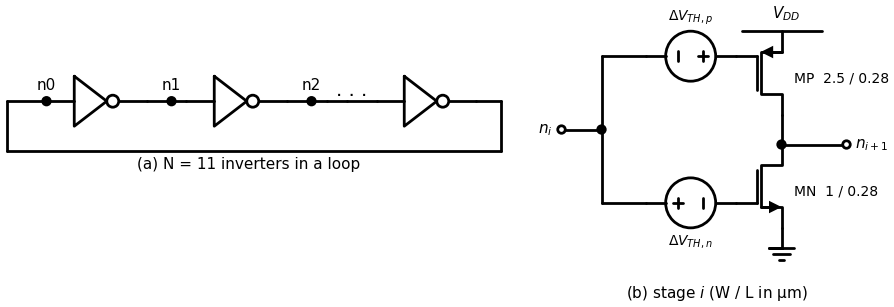

In [4]:
import sys
try:
    import schemdraw
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "schemdraw==0.23"], check=True)
    import schemdraw
import schemdraw.elements as elm
import schemdraw.logic as logic

schemdraw.use("matplotlib")


def nmos(d, drain, gate="left", label=None):
    # nMOS placed by its drain, gate on the left or right; returns the element (anchors drain, gate, source)
    e = elm.AnalogNFet().theta(180).flip() if gate == "left" else elm.AnalogNFet().theta(0)
    e = d.add(e.anchor("drain").at(drain))
    if label:
        dx = 0.35 if gate == "left" else -0.35
        d.add(elm.Label().at((drain[0] + dx, drain[1] - 0.83))
              .label(label, fontsize=10, halign="left" if gate == "left" else "right"))
    return e


def pmos(d, source, gate="left", label=None):
    # pMOS placed by its source
    e = elm.AnalogPFet().theta(180).flip() if gate == "left" else elm.AnalogPFet().theta(0)
    e = d.add(e.anchor("source").at(source))
    if label:
        dx = 0.35 if gate == "left" else -0.35
        d.add(elm.Label().at((source[0] + dx, source[1] - 0.83))
              .label(label, fontsize=10, halign="left" if gate == "left" else "right"))
    return e


with schemdraw.Drawing(unit=2) as d:
    d.config(fontsize=11)
    # (a) the loop
    d += elm.Line().at((0, 0)).right(0.8)
    d += elm.Dot().label("n0", loc="top")
    for name in ["n1", "n2", None, "n0"]:
        if name is None:
            d += elm.Line().right(0.4)
            d += elm.Label().label("· · ·", fontsize=14)
            d += elm.Line().right(0.6)
            continue
        d += logic.Not().right()
        d += elm.Line().right(0.5)
        if name != "n0":
            d += elm.Dot().label(name, loc="top")
            d += elm.Line().right(0.3)
    end = d.here
    d += elm.Line().at(end).down(1.0)
    d += elm.Line().left().tox(0)
    d += elm.Line().up(1.0)
    d += elm.Label().at((end[0] / 2, -1.35)).label("(a) N = 11 inverters in a loop", fontsize=11)
    # (b) stage i with the aging sources of section 4
    x, top = 15.5, 1.4
    d += elm.Line().at((x - 0.8, top)).to((x + 0.8, top))
    d += elm.Label().at((x, top + 0.25)).label("$V_{DD}$")
    mp = pmos(d, (x, top), label="MP  2.5 / 0.28")
    d += elm.Line().at(mp.drain).down(0.6)
    out = d.here
    d += elm.Dot()
    d += elm.Line().at(out).right(1.3)
    d += elm.Dot(open=True).label("$n_{i+1}$", loc="right")
    mn = nmos(d, out, label="MN  1 / 0.28")
    d += elm.Ground().at(mn.source)
    xi = x - 3.6
    d += elm.SourceV().at(mp.gate).left().length(1.8).reverse().label("$\\Delta V_{TH,p}$", loc="top", fontsize=10)
    d += elm.Line().left().tox(xi)
    d += elm.SourceV().at(mn.gate).left().length(1.8).label("$\\Delta V_{TH,n}$", loc="bottom", fontsize=10)
    d += elm.Line().left().tox(xi)
    d += elm.Line().at((xi, mp.gate[1])).to((xi, mn.gate[1]))
    ymid = (mp.gate[1] + mn.gate[1]) / 2
    d += elm.Dot().at((xi, ymid))
    d += elm.Line().at((xi, ymid)).left(0.8)
    d += elm.Dot(open=True).label("$n_i$", loc="left")
    d += elm.Label().at((x - 1.2, mn.source[1] - 1.2)).label("(b) stage $i$ (W / L in µm)", fontsize=11)

In [5]:
def ro_netlist(n_stages=11, wn=1.0, wp=2.5, l=0.28, dev="03v3", vdd=3.3, corner="typical",
               temp=27, dvn=0.0, dvp=0.0, t_stop=30e-9, t_step=2e-12, rise_a=10, rise_b=30, mc_seed=None):
    assert n_stages % 2 == 1 and n_stages >= 3
    lines = [header(corner, temp, mc_seed), f"Vdd vdd 0 {vdd}"]
    for i in range(n_stages):
        a, y = f"n{i}", f"n{(i + 1) % n_stages}"
        lines += [f"Vgn{i} {a} gn{i} {dvn}",          # v(gn) = v(a) - dvn
                  f"Vgp{i} gp{i} {a} {dvp}",          # v(gp) = v(a) + dvp
                  f"XMN{i} {y} gn{i} 0 0 nfet_{dev} W={wn}u L={l}u",
                  f"XMP{i} {y} gp{i} vdd vdd pfet_{dev} W={wp}u L={l}u"]
    h = vdd / 2
    lines.append(textwrap.dedent(f'''\
        .ic v(n0)=0 v(n1)={vdd}
        .control
        tran {t_step} {t_stop} uic
        meas tran ta WHEN v(n0)={h} RISE={rise_a}
        meas tran tb WHEN v(n0)={h} RISE={rise_b}
        meas tran iavg AVG i(Vdd) FROM=ta TO=tb
        quit
        .endc
        .end
        '''))
    return "\n".join(lines)


def run_ring(netlist_fn, **kw):
    # Simulates any ring built by netlist_fn; returns f (Hz), period (s), power (W), energy per cycle (J).
    # Doubles the simulated window and time step (up to 4 times) if the ring is too slow for it.
    rise_a, rise_b, vdd = kw.get("rise_a", 10), kw.get("rise_b", 30), kw.get("vdd", 3.3)
    for _ in range(5):
        log = run_spice(netlist_fn(**kw))
        ta, tb, iavg = meas(log, "ta"), meas(log, "tb"), meas(log, "iavg")
        if tb == tb:
            break
        kw["t_stop"] = 2 * kw.get("t_stop", 30e-9)
        kw["t_step"] = 2 * kw.get("t_step", 2e-12)
    if tb != tb:
        print(log[-3000:])
        raise RuntimeError("ring-oscillator simulation failed: ngspice log above")
    period = (tb - ta) / (rise_b - rise_a)
    power = -iavg * vdd
    return {"f": 1 / period, "period": period, "power": power, "e_cycle": power * period}


def run_ro(**kw):
    return run_ring(ro_netlist, **kw)


r = run_ro()
print(f"11-stage ring, typical, 27 C, 3.3 V: f = {r['f']/1e9:.3f} GHz, "
      f"P = {r['power']*1e3:.2f} mW, E/cycle = {r['e_cycle']*1e12:.2f} pJ")

11-stage ring, typical, 27 C, 3.3 V: f = 1.196 GHz, P = 1.22 mW, E/cycle = 1.02 pJ


## 5. First result: frequency versus temperature

Typical corner, 3.3 V, from −40 °C to 125 °C.

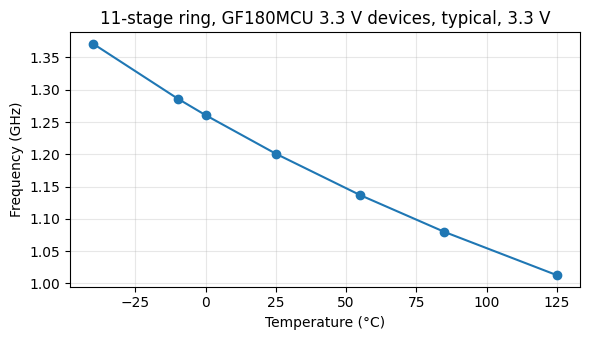

average sensitivity (linear fit, normalized to f at 25 C): -0.179 %/C  (-2.15 MHz/C)
max deviation from a straight line: 8.59 C


In [6]:
temps = np.array([-40, -10, 0, 25, 55, 85, 125])   # same points as the PVT grid
f_T = np.array([run_ro(temp=t)["f"] for t in temps])

slope, intercept = np.polyfit(temps, f_T, 1)
f25 = np.interp(25, temps, f_T)
resid_C = (f_T - (slope * temps + intercept)) / slope       # linearity error expressed in degC

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(temps, f_T / 1e9, "o-")
ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Frequency (GHz)")
ax.set_title("11-stage ring, GF180MCU 3.3 V devices, typical, 3.3 V")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

print(f"average sensitivity (linear fit, normalized to f at 25 C): {slope / f25 * 100:.3f} %/C  ({slope/1e6:.2f} MHz/C)")
print(f"max deviation from a straight line: {np.max(np.abs(resid_C)):.2f} C")

## 6. PVT grid

Five process corners × seven temperatures (−40 to 125 °C) × three supplies (3.3 V ± 10 %) = 105 simulations.
They run in parallel on every CPU core and are cached in `pvt_grid.csv`, so
re-running the cell only reloads the table. Set `RERUN = True` to simulate again.

In [7]:
import itertools, time
import pandas as pd
from concurrent.futures import ThreadPoolExecutor

TEMPS = [-40, -10, 0, 25, 55, 85, 125]   # degC
VDDS = [2.97, 3.30, 3.63]                # V
CSV = os.path.join(WORK, "pvt_grid.csv")
RERUN = False

grid = [(c, t, round(v, 3)) for c, t, v in itertools.product(CORNERS, TEMPS, VDDS)]


def sim_point(p):
    corner, temp, vdd = p
    r = run_ro(corner=corner, temp=temp, vdd=vdd)
    return {"corner": corner, "temp_C": temp, "vdd_V": vdd,
            "f_Hz": r["f"], "power_W": r["power"], "e_cycle_J": r["e_cycle"]}


pvt = pd.read_csv(CSV) if (os.path.exists(CSV) and not RERUN) else None
if pvt is not None and set(zip(pvt.corner, pvt.temp_C, pvt.vdd_V.round(3))) == set(grid):
    print(f"loaded {len(pvt)} points from {CSV}")
else:
    t0, rows = time.time(), []
    with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
        for i, row in enumerate(ex.map(sim_point, grid), 1):
            rows.append(row)
            if i % 15 == 0 or i == len(grid):
                print(f"{i}/{len(grid)} points ({time.time() - t0:.0f} s)", flush=True)
    pvt = pd.DataFrame(rows)
    pvt.to_csv(CSV, index=False)
    print("saved", CSV)

15/105 points (44 s)
30/105 points (88 s)
45/105 points (128 s)
60/105 points (192 s)
75/105 points (241 s)
90/105 points (285 s)
105/105 points (326 s)
saved /content/gf180_work/pvt_grid.csv


### 6.1 Frequency versus temperature across corners and supplies

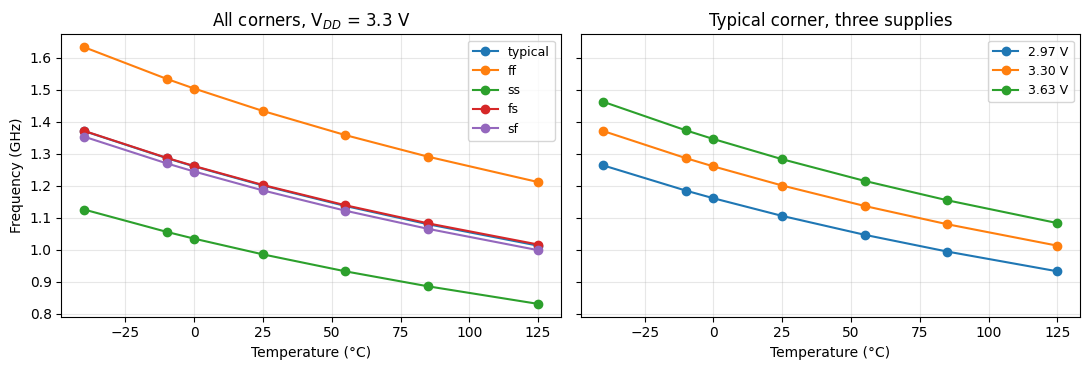

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for c in CORNERS:
    d = pvt[(pvt.corner == c) & np.isclose(pvt.vdd_V, 3.30)].sort_values("temp_C")
    ax1.plot(d.temp_C, d.f_Hz / 1e9, "o-", label=c)
ax1.set_title("All corners, V$_{DD}$ = 3.3 V")
for v in VDDS:
    d = pvt[(pvt.corner == "typical") & np.isclose(pvt.vdd_V, v)].sort_values("temp_C")
    ax2.plot(d.temp_C, d.f_Hz / 1e9, "o-", label=f"{v:.2f} V")
ax2.set_title("Typical corner, three supplies")
for ax in (ax1, ax2):
    ax.set_xlabel("Temperature (°C)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)
ax1.set_ylabel("Frequency (GHz)")
fig.tight_layout()
plt.show()

### 6.2 Sensitivities per corner

For each corner, at the nominal 3.3 V:

- **TC**: slope of a straight-line fit of $f(T)$, normalized to $f$ at 25 °C, in %/°C.
- **Nonlinearity**: largest deviation of $f(T)$ from that line, expressed in °C.
- **$S_V$**: $\dfrac{f(3.63\,\mathrm{V}) - f(2.97\,\mathrm{V})}{0.66\,\mathrm{V}\cdot f(3.3\,\mathrm{V})}$ at 25 °C, in %/V.
- **Temperature error per 10 mV**: $|S_V| \cdot 10\,\mathrm{mV} / |TC|$, the temperature reading error that a
  10 mV supply change causes if the supply is not measured.

In [9]:
rows = []
for c in CORNERS:
    d = pvt[(pvt.corner == c) & np.isclose(pvt.vdd_V, 3.30)].sort_values("temp_C")
    T, f = d.temp_C.to_numpy(), d.f_Hz.to_numpy()
    a, b = np.polyfit(T, f, 1)
    f25 = f[T == 25][0]
    tc = a / f25
    d25 = pvt[(pvt.corner == c) & (pvt.temp_C == 25)].sort_values("vdd_V")
    sv = (d25.f_Hz.iloc[-1] - d25.f_Hz.iloc[0]) / (d25.vdd_V.iloc[-1] - d25.vdd_V.iloc[0]) / f25
    rows.append({"corner": c,
                 "f @25C (GHz)": f25 / 1e9,
                 "TC (%/C)": tc * 100,
                 "nonlinearity (C)": np.max(np.abs(f - (a * T + b))) / abs(a),
                 "S_V (%/V)": sv * 100,
                 "T error per 10 mV (C)": abs(sv * 0.01 / tc),
                 "E/cycle @25C (pJ)": d25.e_cycle_J.iloc[1] * 1e12})
summary = pd.DataFrame(rows).set_index("corner").round(3)
try:
    display(summary)
except NameError:   # outside Jupyter
    print(summary.to_string())

,f @25C (GHz),TC (%/C),nonlinearity (C),S_V (%/V),T error per 10 mV (C),E/cycle @25C (pJ)
corner,,,,,,
typical,1.201,-0.179,8.585,22.353,1.247,1.022
ff,1.434,-0.177,8.361,18.980,1.074,1.025
ss,0.986,-0.180,8.638,25.749,1.432,1.024
fs,1.203,-0.177,8.709,23.003,1.296,1.019
sf,1.186,-0.180,8.406,21.876,1.216,1.025


### 6.3 Read-out polynomial order

Each chip is calibrated at 25 °C, and the ratio $x = \ln(f/f_{25})$ is mapped to temperature by one polynomial
whose coefficients come from the typical corner (3.3 V). The table gives the largest temperature error per corner
for three polynomial orders; the other four corners are out-of-sample.

In [10]:
nom = pvt[np.isclose(pvt.vdd_V, 3.30)].copy()
f25 = nom[nom.temp_C == 25].set_index("corner").f_Hz
nom["x"] = np.log(nom.f_Hz / nom.corner.map(f25))
typ_nom = nom[nom.corner == "typical"]

orders = {}
for n, name in ((1, "linear"), (2, "quadratic"), (3, "cubic")):
    coef = np.polyfit(typ_nom.x, typ_nom.temp_C, n)
    err = (np.polyval(coef, nom.x) - nom.temp_C).abs()
    orders[name] = err.groupby(nom.corner).max()
order_table = pd.DataFrame(orders).T[CORNERS].round(2)
order_table.index.name = "max |error| (C)"
try:
    display(order_table)
except NameError:
    print(order_table.to_string())

corner,typical,ff,ss,fs,sf
max |error| (C),,,,,
linear,4.32,5.27,4.58,5.41,4.33
quadratic,0.13,1.34,0.44,1.50,0.66
cubic,0.00,1.25,0.31,1.41,0.77


### 6.4 Interpretation

**Process shifts the frequency, not its temperature slope.** Across the five corners the frequency at 25 °C spans
0.99 to 1.43 GHz (about ±18 %), while TC only spans −0.177 to −0.180 %/°C (about ±1 %). Most process variations
($C_{ox}$, $\mu_0$, $W/L$) scale the drain current by a constant factor $K$, so $\ln f = \ln K + g(T)$: $K$ moves
the curve up or down but leaves its slope unchanged. A $V_{TH}$ shift changes the overdrive slightly, which is where
the ±1 % comes from. One calibration point per chip (25 °C) and the ratio $x = \ln(f/f_{25})$ therefore remove the
process offset; the remaining slope spread costs about $0.017 \cdot |T - 25\,°C|$, roughly 1.7 °C at 100 °C from
the calibration point.

**One shared quadratic is enough for the curvature.** $f(T)$ deviates by up to 8.4–8.7 °C from a straight line,
with the same bowed shape in every corner, so a single read-out polynomial with coefficients from the typical corner
serves every chip; only the calibration point is measured per chip. Section 6.3 shows that a quadratic brings the
error from about 5 °C (linear) to 1.5 °C or less in every corner, while a cubic mainly improves the typical corner it
was fitted on (the other corners change by about 0.1 °C, and sf gets slightly worse). The quadratic is the better-justified choice (fewer coefficients, less over-fitting). The remaining
1.3–1.5 °C in ff and fs comes from the TC spread, not from the polynomial order.

**The supply, not the process, limits ring A.** A 10 mV supply change reads as 1.1–1.4 °C. With a ±5 % regulator
(±165 mV) the temperature error is about ±21 °C, and with ±10 % (±330 mV) about ±41 °C. Reaching ±2 °C would
require knowing $V_{DD}$ within about ±16 mV (0.5 %). Either the supply is regulated that tightly, or it is
measured, which is the job of ring B (section 7).

## 7. Ring B: separating temperature from supply

Section 6 shows that ring A alone cannot tell a temperature change from a supply change: 10 mV of $V_{DD}$
reads as 1.1–1.4 °C. Ring B is a current-starved ring whose current comes from a poly resistor:

- **Bias.** A `ppolyf_u_1k` resistor (1 kΩ/□, ±20 % across the `res_*` corners, first-order TC of
  −0.94·10⁻³/°C in the model) feeds a stack of diode-connected devices, so
  $I_B \approx \big(V_{DD} - \sum V_{GS}\big)/R$. The bottom device is an nMOS diode that sets the starving
  gate voltage; a mirror copies $I_B$ into a diode-connected pMOS for the other side.
- **Stages.** Every inverter is starved on both sides by devices with $L = 1\,\mu$m, so
  $t_{pd} \approx C\,V_{DD}/(2 I_B)$ and $f_B \propto I_B / (C\,V_{DD})$.

The supply enters twice, through $I_B$ (up) and through the swing $V_{DD}$ (down). Three bias stacks are compared:

| `bias` | stack under the resistor | expected effect |
|---|---|---|
| `"n"` | one nMOS diode | the swing term wins: negative supply sensitivity |
| `"nn"` | two nMOS diodes | $I_B$ grows faster than $V_{DD}$: the sign flips |
| `"pn"` | one pMOS diode over one nMOS diode | same flip, and a fast nMOS / slow pMOS (fs, sf) partly cancel in $\sum V_{GS}$ |

Section 7.1 shows that the choice decides both whether the pair can be inverted and how much ring B moves with
process. `"pn"` is the design used from 7.2 on.

Resistor corners are paired with MOS corners as ff → `res_ff`, ss → `res_ss`, and typical/fs/sf →
`res_typical`. Mixed combinations (for example ss MOS with `res_ff`) are not covered here.

The schematic below is the `"pn"` version. $I_B$ flows through R, MPD and MNB; MNB's gate voltage (`nb`) sets the
nMOS starving devices, and MNM copies $I_B$ into MPB, whose gate voltage (`pb`) sets the pMOS starving devices.
Bodies go to ground (nMOS) and $V_{DD}$ (pMOS), except MPD, whose body is tied to its source. The aging sources of
section 4 are also present in every stage, but omitted from the drawing.

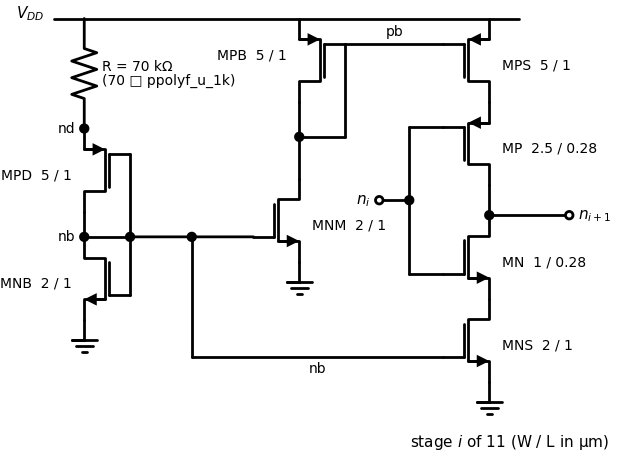

In [11]:
with schemdraw.Drawing(unit=2) as d:
    d.config(fontsize=11)
    d += elm.Line().at((-0.6, 0)).to((8.7, 0))
    d += elm.Label().at((-0.9, 0)).label("$V_{DD}$", halign="right")
    # bias: R over the pMOS-over-nMOS diode stack
    d += elm.Resistor().at((0, 0)).down(2.2).label("R = 70 kΩ\n(70 □ ppolyf_u_1k)", loc="bottom", fontsize=10)
    d += elm.Dot().label("nd", loc="left", fontsize=10)
    mpd = pmos(d, d.here, gate="right", label="MPD  5 / 1")
    d += elm.Line().at(mpd.drain).down(0.5)
    nb = d.here
    d += elm.Dot().label("nb", loc="left", fontsize=10)
    mnb = nmos(d, nb, gate="right", label="MNB  2 / 1")
    d += elm.Ground().at(mnb.source)
    xg = mpd.gate[0]
    d += elm.Line().at(mpd.gate).to((xg, mnb.gate[1]))
    d += elm.Line().at(nb).to((xg, nb[1]))
    d += elm.Dot().at((xg, nb[1]))
    # mirror: MNM copies I_B into the pMOS diode MPB
    xm = 4.3
    mpb = pmos(d, (xm, 0), gate="right", label="MPB  5 / 1")
    d += elm.Line().at(mpb.drain).down(0.7)
    pb = d.here
    d += elm.Dot()
    d += elm.Line().at(pb).to((mpb.gate[0], pb[1]))
    d += elm.Line().to(mpb.gate)
    mnm = nmos(d, (xm, nb[1] + 1.167), gate="left", label="MNM  2 / 1")
    d += elm.Line().at(pb).to(mnm.drain)
    d += elm.Line().at((xg, nb[1])).to(mnm.gate)
    d += elm.Ground().at(mnm.source)
    # one starved stage
    xs = 8.1
    mps = pmos(d, (xs, 0), label="MPS  5 / 1")
    d += elm.Line().at(mpb.gate).to(mps.gate).label("pb", loc="top", fontsize=10)
    mp = pmos(d, mps.drain, label="MP  2.5 / 0.28")
    d += elm.Line().at(mp.drain).down(0.6)
    out = d.here
    d += elm.Dot()
    d += elm.Line().at(out).right(1.6)
    d += elm.Dot(open=True).label("$n_{i+1}$", loc="right")
    mn = nmos(d, out, label="MN  1 / 0.28")
    mns = nmos(d, mn.source, label="MNS  2 / 1")
    d += elm.Ground().at(mns.source)
    xi = xs - 1.6
    d += elm.Line().at(mp.gate).to((xi, mp.gate[1]))
    d += elm.Line().to((xi, mn.gate[1]))
    d += elm.Line().to(mn.gate)
    d += elm.Dot().at((xi, (mp.gate[1] + mn.gate[1]) / 2))
    d += elm.Line().left(0.6)
    d += elm.Dot(open=True).label("$n_i$", loc="left")
    xr = (mnm.gate[0] + xg) / 2
    d += elm.Dot().at((xr, nb[1]))
    d += elm.Line().at((xr, nb[1])).to((xr, mns.gate[1]))
    d += elm.Line().at((xr, mns.gate[1])).to(mns.gate).label("nb", loc="bottom", fontsize=10)
    d += elm.Label().at((xs + 0.3, mns.source[1] - 1.3)).label("stage $i$ of 11 (W / L in µm)", fontsize=11)

In [12]:
RES_CORNER = {"typical": "res_typical", "ff": "res_ff", "ss": "res_ss", "fs": "res_typical", "sf": "res_typical"}


def csro_netlist(n_stages=11, bias="pn", r_sq=70, r_w=1.0, wn=1.0, wp=2.5, l=0.28, wsn=2.0, wsp=5.0,
                 ls=1.0, vdd=3.3, corner="typical", temp=27, dvn=0.0, dvp=0.0, t_stop=1.2e-6,
                 t_step=50e-12, rise_a=10, rise_b=30, mc_seed=None, wmir=None, lmir=None, wmns=None, lmns=None):
    # wmir, lmir: optional size of the shared nMOS mirror devices MNB and MNM; wmns, lmns: of the 11 MNS (section 7.8)
    assert n_stages % 2 == 1 and bias in ("n", "nn", "pn")
    wm, lm, wns, lns = (wmir or wsn), (lmir or ls), (wmns or wsn), (lmns or ls)
    top = "nb" if bias == "n" else "nd"
    lines = [header(corner, temp, mc_seed),
             f'.lib "{GF180_MODELS}/sm141064.spice" {RES_CORNER[corner]}',
             f"Vdd vdd 0 {vdd}",
             f"XR vdd {top} 0 ppolyf_u_1k r_length={r_sq * r_w}u r_width={r_w}u",   # R = r_sq squares
             f"XMNB nb nb 0 0 nfet_03v3 W={wm}u L={lm}u"]                           # diode, mirror reference
    if bias == "nn":
        lines.append(f"XMND nd nd nb 0 nfet_03v3 W={wsn}u L={ls}u")                 # stacked nMOS diode
    elif bias == "pn":
        lines.append(f"XMPD nb nb nd nd pfet_03v3 W={wsp}u L={ls}u")                # stacked pMOS diode
    lines += [f"XMNM pb nb 0 0 nfet_03v3 W={wm}u L={lm}u",                          # mirror into the pMOS diode
              f"XMPB pb pb vdd vdd pfet_03v3 W={wsp}u L={ls}u"]
    for i in range(n_stages):
        a, y = f"n{i}", f"n{(i + 1) % n_stages}"
        lines += [f"Vgn{i} {a} gn{i} {dvn}",
                  f"Vgp{i} gp{i} {a} {dvp}",
                  f"XMPS{i} sp{i} pb vdd vdd pfet_03v3 W={wsp}u L={ls}u",           # starving pMOS
                  f"XMNS{i} sn{i} nb 0 0 nfet_03v3 W={wns}u L={lns}u",              # starving nMOS
                  f"XMN{i} {y} gn{i} sn{i} 0 nfet_03v3 W={wn}u L={l}u",
                  f"XMP{i} {y} gp{i} sp{i} vdd pfet_03v3 W={wp}u L={l}u"]
    h = vdd / 2
    lines.append(textwrap.dedent(f'''\
        .ic v(n0)=0 v(n1)={vdd}
        .control
        tran {t_step} {t_stop} uic
        meas tran ta WHEN v(n0)={h} RISE={rise_a}
        meas tran tb WHEN v(n0)={h} RISE={rise_b}
        meas tran iavg AVG i(Vdd) FROM=ta TO=tb
        quit
        .endc
        .end
        '''))
    return "\n".join(lines)


def run_csro(**kw):
    kw.setdefault("t_stop", 1.2e-6)
    kw.setdefault("t_step", 50e-12)
    return run_ring(csro_netlist, **kw)


r = run_csro()
print(f"ring B, typical, 27 C, 3.3 V: f = {r['f']/1e6:.2f} MHz, P = {r['power']*1e6:.0f} uW "
      f"(bias branches included)")

ring B, typical, 27 C, 3.3 V: f = 46.92 MHz, P = 184 uW (bias branches included)


### 7.1 Choosing the bias stack

Around 25 °C and 3.3 V each ring gives one row of

$$\begin{bmatrix}\Delta f_A/f_A\\ \Delta f_B/f_B\end{bmatrix} = S\begin{bmatrix}\Delta T\\ \Delta V_{DD}\end{bmatrix}.$$

The condition number of $S$ (typical corner, columns scaled by the operating ranges of 165 °C and 0.66 V) says how
much a relative frequency error is amplified when the pair is inverted: close to 1 is good, large means both rings
see almost the same thing. The spread of ring B's own TC and $S_V$ over the five corners says how well a model
fitted on one corner will transfer to the others. Finite differences of ±25 °C and ±0.1 V.

In [13]:
def sensitivities(run_fn, corner="typical", **kw):
    pts = {"f0": (25, 3.3), "tp": (50, 3.3), "tm": (0, 3.3), "vp": (25, 3.4), "vm": (25, 3.2)}
    f = {k: run_fn(corner=corner, temp=t, vdd=v, **kw)["f"] for k, (t, v) in pts.items()}
    return f["f0"], (f["tp"] - f["tm"]) / 50 / f["f0"], (f["vp"] - f["vm"]) / 0.2 / f["f0"]


RANGES = np.array([165.0, 0.66])
fA, tA, vA = sensitivities(run_ro)
jobs = [(b, c) for b in ("n", "nn", "pn") for c in CORNERS]
with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
    sens_b = dict(zip(jobs, ex.map(lambda j: sensitivities(run_csro, corner=j[1], bias=j[0]), jobs)))

rows = [{"ring": "A (plain)", "f typical (MHz)": fA / 1e6, "TC typical (%/C)": tA * 100,
         "S_V typical (%/V)": vA * 100, "cond(S) with A": np.nan,
         "TC over corners (%/C)": "", "S_V over corners (%/V)": ""}]
for b in ("n", "nn", "pn"):
    fB, tB, vB = sens_b[(b, "typical")]
    tcs = [100 * sens_b[(b, c)][1] for c in CORNERS]
    svs = [100 * sens_b[(b, c)][2] for c in CORNERS]
    rows.append({"ring": f"B, bias='{b}'", "f typical (MHz)": fB / 1e6, "TC typical (%/C)": tB * 100,
                 "S_V typical (%/V)": vB * 100,
                 "cond(S) with A": np.linalg.cond(np.array([[tA, vA], [tB, vB]]) * RANGES),
                 "TC over corners (%/C)": f"{min(tcs):+.3f} to {max(tcs):+.3f}",
                 "S_V over corners (%/V)": f"{min(svs):+.1f} to {max(svs):+.1f}"})
sens_table = pd.DataFrame(rows).set_index("ring").round(3)
try:
    display(sens_table)
except NameError:
    print(sens_table.to_string())

,f typical (MHz),TC typical (%/C),S_V typical (%/V),cond(S) with A,TC over corners (%/C),S_V over corners (%/V)
ring,,,,,,
A (plain),1200.854,-0.189,22.248,NaN,,
"B, bias='n'",103.585,0.055,-8.414,33.470,+0.046 to +0.062,-9.3 to -6.6
"B, bias='nn'",43.279,0.084,25.487,1.696,+0.069 to +0.104,+16.1 to +37.4
"B, bias='pn'",46.857,0.071,20.244,2.072,+0.063 to +0.081,+16.4 to +26.1


### 7.2 PVT grid for ring B (bias = 'pn')

Same 105 points as section 6, cached in `pvt_grid_b_pn.csv`.

In [14]:
B_BIAS = "pn"                                        # bias stack chosen in 7.1
CSV_B = os.path.join(WORK, f"pvt_grid_b_{B_BIAS}.csv")


def sim_point_b(p):
    corner, temp, vdd = p
    r = run_csro(corner=corner, temp=temp, vdd=vdd, bias=B_BIAS)
    return {"corner": corner, "temp_C": temp, "vdd_V": vdd,
            "f_Hz": r["f"], "power_W": r["power"], "e_cycle_J": r["e_cycle"]}


pvt_b = pd.read_csv(CSV_B) if (os.path.exists(CSV_B) and not RERUN) else None
if pvt_b is not None and set(zip(pvt_b.corner, pvt_b.temp_C, pvt_b.vdd_V.round(3))) == set(grid):
    print(f"loaded {len(pvt_b)} points from {CSV_B}")
else:
    t0, rows = time.time(), []
    with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
        for i, row in enumerate(ex.map(sim_point_b, grid), 1):
            rows.append(row)
            if i % 15 == 0 or i == len(grid):
                print(f"{i}/{len(grid)} points ({time.time() - t0:.0f} s)", flush=True)
    pvt_b = pd.DataFrame(rows)
    pvt_b.to_csv(CSV_B, index=False)
    print("saved", CSV_B)

15/105 points (122 s)
30/105 points (231 s)
45/105 points (351 s)
60/105 points (454 s)
75/105 points (573 s)
90/105 points (681 s)
105/105 points (794 s)
saved /content/gf180_work/pvt_grid_b_pn.csv


### 7.3 Temperature read-out across corners

Each chip is calibrated at **one temperature**, 25 °C. Afterwards only frequency ratios are used:
$x_A = \ln(f_A/f_{A,cal})$ and $x_B = \ln(f_B/f_{B,cal})$, with the calibration frequencies taken at 25 °C and 3.3 V.
Three read-outs are compared:

1. **Ring A alone.** A quadratic $\hat T(x_A)$, as chosen in section 6.3. It cannot see the supply.
2. **A + B, one-point calibration.** Quadratic surfaces $\hat T(x_A, x_B)$ and $\hat V_{DD}(x_A, x_B)$.
3. **A + B with a supply trim.** At the same 25 °C step the tester also sets $V_{DD}$ to 2.97 and 3.63 V, which
   costs two extra readings and no extra temperature. That gives each chip's own supply slopes $v_A$, $v_B$, and
   $z = x_A - (v_A/v_B)\,x_B$ has no first-order supply dependence. $\hat T$ is a cubic in $z$ plus small $x_B$
   terms (why cubic here: section 7.4).

All models are fitted only on the typical corner (all 21 temperature/supply points; ring A alone only at 3.3 V), so
the other four corners are out-of-sample tests.

,"1) A alone, 3.3 V only (C)","1) A alone, 3.3 V +/-10 % (C)","2) A + B, 1-point (C)","2) A + B, 1-point: V_DD (mV)",3) A + B + supply trim (C)
corner,,,,,
typical,0.13,54.98,1.38,11.18,0.84
ff,1.34,45.43,7.80,99.93,4.90
ss,0.44,62.92,7.49,111.22,2.00
fs,1.50,54.88,3.68,10.51,1.33
sf,0.66,54.67,2.58,11.13,1.10


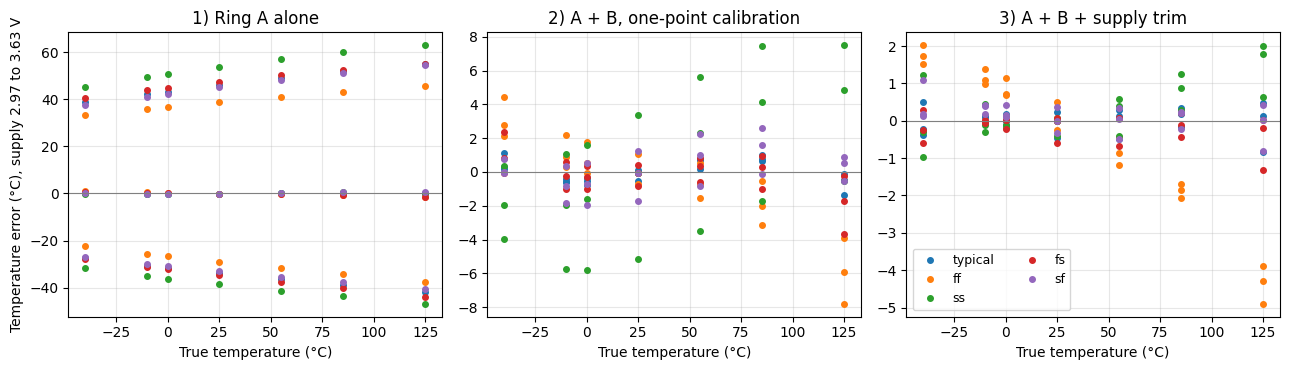

In [15]:
m = pvt.merge(pvt_b, on=["corner", "temp_C", "vdd_V"], suffixes=("_A", "_B"))
cal = m[(m.temp_C == 25) & np.isclose(m.vdd_V, 3.30)].set_index("corner")
m["xA"] = np.log(m.f_Hz_A / m.corner.map(cal.f_Hz_A))
m["xB"] = np.log(m.f_Hz_B / m.corner.map(cal.f_Hz_B))

# supply trim: per-chip slopes d x / d VDD measured at 25 C only
d25 = m[m.temp_C == 25].sort_values("vdd_V")
v_A = d25.groupby("corner").xA.apply(lambda x: (x.iloc[-1] - x.iloc[0]) / 0.66)
v_B = d25.groupby("corner").xB.apply(lambda x: (x.iloc[-1] - x.iloc[0]) / 0.66)
m["z"] = m.xA - m.corner.map(v_A / v_B) * m.xB


def basis_a(xa):
    return np.column_stack([np.ones_like(xa), xa, xa**2])


def basis_ab(xa, xb):
    return np.column_stack([np.ones_like(xa), xa, xb, xa**2, xa * xb, xb**2])


def basis_trim(z, xb):
    return np.column_stack([np.ones_like(z), z, z**2, z**3, xb, xb**2, z * xb])


def fitted(basis, cols, target, mask):
    X = basis(*[m[c].to_numpy() for c in cols])
    coef = np.linalg.lstsq(X[mask.to_numpy()], m[target][mask].to_numpy(), rcond=None)[0]
    return X @ coef


typ = m.corner == "typical"
nominal = np.isclose(m.vdd_V, 3.30)
m["eT_A"] = fitted(basis_a, ["xA"], "temp_C", typ & nominal) - m.temp_C
m["eT_AB"] = fitted(basis_ab, ["xA", "xB"], "temp_C", typ) - m.temp_C
m["eV_AB"] = fitted(basis_ab, ["xA", "xB"], "vdd_V", typ) - m.vdd_V
m["eT_trim"] = fitted(basis_trim, ["z", "xB"], "temp_C", typ) - m.temp_C


def worst(col, rows=None):
    d = m if rows is None else m[rows]
    return d.groupby("corner")[col].apply(lambda e: e.abs().max())


readout = pd.DataFrame({
    "1) A alone, 3.3 V only (C)": worst("eT_A", nominal),
    "1) A alone, 3.3 V +/-10 % (C)": worst("eT_A"),
    "2) A + B, 1-point (C)": worst("eT_AB"),
    "2) A + B, 1-point: V_DD (mV)": 1e3 * worst("eV_AB"),
    "3) A + B + supply trim (C)": worst("eT_trim"),
}).reindex(CORNERS).round(2)
try:
    display(readout)
except NameError:
    print(readout.to_string())

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
titles = ["1) Ring A alone", "2) A + B, one-point calibration", "3) A + B + supply trim"]
for ax, col, title in zip(axes, ["eT_A", "eT_AB", "eT_trim"], titles):
    for c in CORNERS:
        d = m[m.corner == c]
        ax.plot(d.temp_C, d[col], "o", ms=4, label=c)
    ax.axhline(0, color="0.5", lw=0.8)
    ax.set_title(title)
    ax.set_xlabel("True temperature (°C)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Temperature error (°C), supply 2.97 to 3.63 V")
axes[2].legend(fontsize=9, ncol=2)
fig.tight_layout()
plt.show()

### 7.4 Interpretation

**The bias stack sets the direction of ring B's sensitivity vector.** Separability is the ability to tell, from the
two measured frequencies, how much of a change came from temperature and how much from the supply, that is, the
ability to invert $S$; its condition number measures how much errors are amplified on the way. Ring A has
TC < 0 and $S_V$ > 0. With bias `'n'` ring B has the opposite sign in both (TC > 0, $S_V$ < 0), so its vector points
the other way along the same line as A and the pair is close to singular (condition number ≈ 33). Stacking two
diodes makes $I_B$ grow faster than $V_{DD}$, which turns $S_V$ positive while TC stays positive: `'nn'` and `'pn'`
are very different from A and similar to each other at the typical corner (1.7 and 2.1). Between those two, `'pn'`
keeps $S_V$ within 16.4–26.1 %/V over the corners, against 16.1–37.4 %/V for `'nn'`, because in fs and sf the nMOS
and pMOS shifts cancel in $V_{GS,n} + |V_{GS,p}|$. That robustness is worth the slightly higher condition number,
so `'pn'` is the design.

**The typical-corner error is a training error.** The read-out coefficients are fitted on the typical corner, so
its 0.8 °C (with the supply trim) is an optimistic, in-sample figure; the other four corners are the real
validation. On them, ring A alone reaches 45–63 °C of error over a ±10 % supply, A + B with one-point calibration
stays within about 8 °C, and the supply trim brings fs, sf and ss to about 1–2 °C and ff to about 5 °C.

**Why ff and ss are the hardest corners.** In fs and sf one $V_{GS}$ goes up while the other goes down, so ring B
behaves almost as in the typical corner. In ff and ss both move the same way: the stack voltage changes, and with it
$I_B$ and ring B's $S_V$ (16.4 and 26.1 %/V against 20.2 %/V typical). The supply trim measures each chip's $S_V$,
so most of that is corrected. What remains is ring B's TC, which also changes with the corner (0.063 to
0.081 %/°C) and cannot be measured with a single-temperature calibration; that is the ≈5 °C left in ff.

**Model order.** Unlike ring A alone, the two-ring read-out benefits from a cubic term in $z$: fs and sf improve by
about 0.5 °C over a quadratic. Because this choice was made by looking at the non-typical corners, they act partly
as a selection set; an independent Monte Carlo test set would be the clean validation.

### 7.5 Mismatch Monte Carlo

The corners of 7.3 move every device of a die together. Mismatch is the random difference between nominally
identical devices on the same die. The GF180MCU models include it: each device gets its own threshold and mobility
offset, with a standard deviation proportional to $1/\sqrt{WL}$ (Pelgrom's law), switched on with
`sw_stat_mismatch=1`. With a fixed `.options seed`, ngspice draws the same values in every run of the same netlist,
so one seed is one chip that can be calibrated at 25 °C and measured later at other temperatures and supplies (the
temperature and supply are plain numbers in the netlist and do not change the random draws). Rings A and B of a chip
use different seeds, so their mismatch is independent.

Each of `N_MC` chips sits on the typical corner with mismatch on and is simulated at −40, 25 and 125 °C at the three
supplies, 9 points per ring. Every chip gets its own one-point calibration and supply trim, exactly as in 7.3, and
the read-out coefficients are the ones fitted on the nominal typical corner: nothing is refitted. Global process
variation is covered by the corners; this section measures what mismatch adds on top. With `N_MC = 16` this is 288
simulations, cached in `mc_mismatch_16.csv`.

In [16]:
N_MC = 16                     # chips; more chips give a tighter estimate of the 3-sigma spread
MC_TEMPS = [-40, 25, 125]
CSV_MC = os.path.join(WORK, f"mc_mismatch_{N_MC}.csv")

# 1-sigma mismatch of one device, from the formulas of the fets_mm section of sm141064.spice
# (pair coefficients 7.148 / 6.660 mV*um for V_TH and 0.7008 / 0.2833 %*um for mobility, nMOS / pMOS;
#  L_eff = L - 0.15 um, W_eff = W + 0.1 um)
def device_sigma(w, l, pmos):
    root_area = np.sqrt((l - 0.15) * (w + 0.1))
    a_vt, a_mu = (6.660, 0.2833) if pmos else (7.148, 0.7008)
    return 0.7071 * a_vt / root_area, 0.7071 * a_mu / root_area


dev_rows = []
for name, w, l, pmos in [("MN (inverter)", 1.0, 0.28, False), ("MP (inverter)", 2.5, 0.28, True),
                         ("MNS, MNB, MNM (ring B bias)", 2.0, 1.0, False),
                         ("MPS, MPD, MPB (ring B bias)", 5.0, 1.0, True)]:
    s_vt, s_mu = device_sigma(w, l, pmos)
    dev_rows.append({"device": name, "W/L (um)": f"{w:g}/{l:g}", "sigma V_TH (mV)": s_vt, "sigma mobility (%)": s_mu})
devices = pd.DataFrame(dev_rows).set_index("device").round(2)
try:
    display(devices)
except NameError:
    print(devices.to_string())


def mc_point(job):
    chip, ring, temp, vdd = job
    if ring == "A":
        r = run_ro(temp=temp, vdd=vdd, mc_seed=1000 + chip)
    else:   # 0.9 us holds 30 cycles of ring B at the typical corner; results are identical to the 1.2 us window
        r = run_csro(bias=B_BIAS, temp=temp, vdd=vdd, mc_seed=2000 + chip, t_stop=0.9e-6)
    return {"chip": chip, "ring": ring, "temp_C": temp, "vdd_V": vdd, "f_Hz": r["f"]}


mc_jobs = [(c, ring, t, v) for c in range(N_MC) for ring in ("A", "B") for t in MC_TEMPS for v in VDDS]
mc_raw = pd.read_csv(CSV_MC) if (os.path.exists(CSV_MC) and not RERUN) else None
if mc_raw is not None and len(mc_raw) == len(mc_jobs):
    print(f"loaded {len(mc_raw)} simulations from {CSV_MC}")
else:
    t0, rows = time.time(), []
    with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
        for i, row in enumerate(ex.map(mc_point, mc_jobs), 1):
            rows.append(row)
            if i % 36 == 0 or i == len(mc_jobs):
                print(f"{i}/{len(mc_jobs)} simulations ({time.time() - t0:.0f} s)", flush=True)
    mc_raw = pd.DataFrame(rows)
    mc_raw.to_csv(CSV_MC, index=False)
    print("saved", CSV_MC)

,W/L (um),sigma V_TH (mV),sigma mobility (%)
device,,,
MN (inverter),1/0.28,13.37,1.31
MP (inverter),2.5/0.28,8.10,0.34
"MNS, MNB, MNM (ring B bias)",2/1,3.78,0.37
"MPS, MPD, MPB (ring B bias)",5/1,2.26,0.10


36/288 simulations (159 s)
72/288 simulations (320 s)
108/288 simulations (483 s)
144/288 simulations (648 s)
180/288 simulations (813 s)
216/288 simulations (980 s)
252/288 simulations (1140 s)
288/288 simulations (1297 s)
saved /content/gf180_work/mc_mismatch_16.csv


spread over 16 chips (1 sigma): f at 25 C, 3.3 V: ring A 0.22 %, ring B 2.41 %; supply slope: ring A 0.09 %/V (mean 22.5), ring B 0.76 %/V (mean 20.5)


,no mismatch: max |error| (C),MC: max |mean| (C),MC: max 3 sigma (C),"MC: worst chip, max |error| (C)"
"A alone, 3.3 V",0.11,0.12,0.33,0.31
"A alone, 3.3 V +/-10 %",54.98,54.93,0.73,55.38
"A + B + supply trim, 3.3 V +/-10 %",0.84,1.55,8.02,5.39
"same, mismatch in ring A only",0.84,0.86,0.43,1.15
"same, mismatch in ring B only",0.84,1.53,8.04,5.47


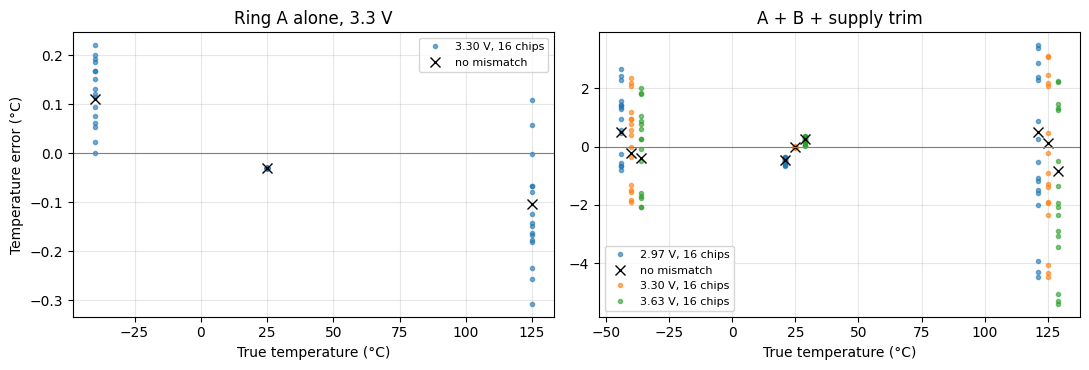

In [17]:
# per-chip calibration and supply trim, exactly as in 7.3
mc = (mc_raw.assign(vdd_V=mc_raw.vdd_V.round(2))
      .pivot_table(index=["chip", "temp_C", "vdd_V"], columns="ring", values="f_Hz").reset_index())
mc.columns.name = None
mc = mc.rename(columns={"A": "f_A", "B": "f_B"})
cal_mc = mc[(mc.temp_C == 25) & np.isclose(mc.vdd_V, 3.30)].set_index("chip")
mc["xA"] = np.log(mc.f_A / mc.chip.map(cal_mc.f_A))
mc["xB"] = np.log(mc.f_B / mc.chip.map(cal_mc.f_B))
s25 = mc[mc.temp_C == 25].sort_values("vdd_V")
vA_mc = s25.groupby("chip").xA.apply(lambda x: (x.iloc[-1] - x.iloc[0]) / 0.66)
vB_mc = s25.groupby("chip").xB.apply(lambda x: (x.iloc[-1] - x.iloc[0]) / 0.66)
mc["z"] = mc.xA - mc.chip.map(vA_mc / vB_mc) * mc.xB

# read-out coefficients fitted on the nominal typical corner (7.3); not refitted
typ_rows = m.corner == "typical"
coef_a = np.linalg.lstsq(basis_a(m.xA[typ_rows & nominal].to_numpy()),
                         m.temp_C[typ_rows & nominal].to_numpy(), rcond=None)[0]
coef_t = np.linalg.lstsq(basis_trim(m.z[typ_rows].to_numpy(), m.xB[typ_rows].to_numpy()),
                         m.temp_C[typ_rows].to_numpy(), rcond=None)[0]
mc["eT_A"] = basis_a(mc.xA.to_numpy()) @ coef_a - mc.temp_C
mc["eT_trim"] = basis_trim(mc.z.to_numpy(), mc.xB.to_numpy()) @ coef_t - mc.temp_C

print(f"spread over {N_MC} chips (1 sigma): f at 25 C, 3.3 V: ring A {100 * cal_mc.f_A.std() / cal_mc.f_A.mean():.2f} %, "
      f"ring B {100 * cal_mc.f_B.std() / cal_mc.f_B.mean():.2f} %; supply slope: ring A {100 * vA_mc.std():.2f} %/V "
      f"(mean {100 * vA_mc.mean():.1f}), ring B {100 * vB_mc.std():.2f} %/V (mean {100 * vB_mc.mean():.1f})")

# same read-out with the mismatch of only one ring (the other ring at its nominal typical value)
typ_pts = m[typ_rows].assign(vdd_V=m.vdd_V.round(2)).set_index(["temp_C", "vdd_V"])
pts = pd.MultiIndex.from_arrays([mc.temp_C, mc.vdd_V])
xA_nom, xB_nom = typ_pts.xA.reindex(pts).to_numpy(), typ_pts.xB.reindex(pts).to_numpy()


def trim_error(xa, xb, k):
    xa, xb, k = np.asarray(xa), np.asarray(xb), np.asarray(k)
    return basis_trim(xa - k * xb, xb) @ coef_t - mc.temp_C.to_numpy()


mc["eT_trim_onlyA"] = trim_error(mc.xA, xB_nom, mc.chip.map(vA_mc) / v_B["typical"])
mc["eT_trim_onlyB"] = trim_error(xA_nom, mc.xB, v_A["typical"] / mc.chip.map(vB_mc))
ref = m[typ_rows & m.temp_C.isin(MC_TEMPS)]
for col in ("eT_trim_onlyA", "eT_trim_onlyB"):
    ref = ref.assign(**{col: ref.eT_trim})


def mc_row(col, only_nominal):
    d = mc[np.isclose(mc.vdd_V, 3.30)] if only_nominal else mc
    r = ref[np.isclose(ref.vdd_V, 3.30)] if only_nominal else ref
    per_point = d.groupby(["temp_C", "vdd_V"])[col]
    return {"no mismatch: max |error| (C)": r[col].abs().max(),
            "MC: max |mean| (C)": per_point.mean().abs().max(),
            "MC: max 3 sigma (C)": 3 * per_point.std().max(),
            "MC: worst chip, max |error| (C)": d[col].abs().max()}


mc_table = pd.DataFrame({"A alone, 3.3 V": mc_row("eT_A", True),
                         "A alone, 3.3 V +/-10 %": mc_row("eT_A", False),
                         "A + B + supply trim, 3.3 V +/-10 %": mc_row("eT_trim", False),
                         "   same, mismatch in ring A only": mc_row("eT_trim_onlyA", False),
                         "   same, mismatch in ring B only": mc_row("eT_trim_onlyB", False)}).T.round(2)
try:
    display(mc_table)
except NameError:
    print(mc_table.to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, title, vdds in ((axes[0], "eT_A", "Ring A alone, 3.3 V", [3.30]),
                             (axes[1], "eT_trim", "A + B + supply trim", VDDS)):
    for k, v in enumerate(vdds):
        dx = 4 * (k - (len(vdds) - 1) / 2)
        d = mc[np.isclose(mc.vdd_V, v)]
        ax.plot(d.temp_C + dx, d[col], "o", ms=3, alpha=0.6, label=f"{v:.2f} V, {N_MC} chips")
        r = ref[np.isclose(ref.vdd_V, v)]
        ax.plot(r.temp_C + dx, r[col], "kx", ms=7, label="no mismatch" if k == 0 else None)
    ax.axhline(0, color="0.5", lw=0.8)
    ax.set_title(title)
    ax.set_xlabel("True temperature (°C)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
axes[0].set_ylabel("Temperature error (°C)")
fig.tight_layout()
plt.show()

### 7.6 Where ring B's spread comes from, and what predicts it

Ring B's frequency spreads about ten times more than ring A's, and the decomposition above shows that ring B's
mismatch sets the read-out error. To find the devices responsible, the cell below shifts the $|V_{TH}|$ of one group
of ring B devices by one standard deviation (with a gate source, as for aging in section 4) and measures the change in
frequency at 25 °C and in ring B's temperature coefficient, $TC_B = \ln\!\big(f(125)/f(-40)\big)/165$ °C. A single
device acts with its full shift; a group of 11 per-stage devices has independent shifts that average out, so its
contribution is the common-shift effect divided by $\sqrt{11}$ (21 simulations).

In [18]:
def csro_shifted(group, dv):
    # ring B netlist with the gate of every device whose name matches `group` behind a dv source:
    # nMOS gates see gate - dv and pMOS gates see gate + dv, so |V_TH| is effectively higher by dv
    def netlist(**kw):
        lines = []
        for line in csro_netlist(**kw).splitlines():
            tok = line.split()
            if tok and re.fullmatch(group, tok[0]):
                gate, new = tok[2], f"{tok[2]}_{tok[0]}"
                lines.append(f"V{tok[0]} {new} {gate} {dv}" if "pfet" in line else f"V{tok[0]} {gate} {new} {dv}")
                tok[2] = new
                line = " ".join(tok)
            lines.append(line)
        return "\n".join(lines)
    return netlist


s_n, s_p = device_sigma(2.0, 1.0, False)[0] * 1e-3, device_sigma(5.0, 1.0, True)[0] * 1e-3
groups = {"MNB (reference diode)": ("XMNB", s_n, 1), "MPD (stacked diode)": ("XMPD", s_p, 1),
          "MNM (mirror into MPB)": ("XMNM", s_n, 1), "MPB (pMOS diode)": ("XMPB", s_p, 1),
          "MNS (11, one per stage)": (r"XMNS\d+", s_n, 11), "MPS (11, one per stage)": (r"XMPS\d+", s_p, 11)}


def inj_point(job):
    name, temp = job
    grp, dv, _ = groups.get(name, ("^$", 0.0, 1))
    r = run_ring(csro_shifted(grp, dv), bias=B_BIAS, temp=temp, vdd=3.30, t_stop=0.9e-6, t_step=50e-12)
    return job, r["f"]


with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
    f_inj = dict(ex.map(inj_point, [(k, t) for k in ["none", *groups] for t in (-40, 25, 125)]))


def tc_chord(k):
    return 100 * np.log(f_inj[(k, 125)] / f_inj[(k, -40)]) / 165


inj = pd.DataFrame([{"device": k, "shift (mV)": 1e3 * dv,
                     "f change at 25 C (%)": 100 * np.log(f_inj[(k, 25)] / f_inj[("none", 25)]),
                     "TC_B change (%/C)": tc_chord(k) - tc_chord("none"),
                     "1-sigma share of TC_B (%/C)": (tc_chord(k) - tc_chord("none")) / np.sqrt(n)}
                    for k, (_, dv, n) in groups.items()]).set_index("device")

# ring B's own TC for every Monte Carlo chip, and its calibration frequency relative to the nominal chip
u_B = np.log(cal_mc.f_B / cal.loc["typical", "f_Hz_B"])
xb33 = mc[np.isclose(mc.vdd_V, 3.30)].pivot(index="chip", columns="temp_C", values="xB")
tc_B = 100 * (xb33[125] - xb33[-40]) / 165
print(f"sum of the 1-sigma shares (root-sum-square): {np.sqrt((inj.iloc[:, -1] ** 2).sum()):.4f} %/C; "
      f"Monte Carlo sigma of TC_B: {tc_B.std():.4f} %/C (mean {tc_B.mean():.4f})")
try:
    display(inj.round(4))
except NameError:
    print(inj.round(4).to_string())

sum of the 1-sigma shares (root-sum-square): 0.0073 %/C; Monte Carlo sigma of TC_B: 0.0074 %/C (mean 0.0624)


,shift (mV),f change at 25 C (%),TC_B change (%/C),1-sigma share of TC_B (%/C)
device,,,,
MNB (reference diode),3.7831,2.0769,-0.0062,-0.0062
MPD (stacked diode),2.2618,-0.1725,0.0001,0.0001
MNM (mirror into MPB),3.7831,-1.2148,0.0034,0.0034
MPB (pMOS diode),2.2618,0.5603,-0.0012,-0.0012
"MNS (11, one per stage)",3.7831,-1.1653,0.0029,0.0009
"MPS (11, one per stage)",2.2618,-0.5667,0.0012,0.0004


The same mirror offset that moves ring B's frequency also moves its TC, so the calibration frequency, which every chip
measures anyway, carries information about the TC error. The next cell plots one against the other for the Monte
Carlo chips, with the five process corners for reference, and tests a one-coefficient correction
$\hat T \leftarrow \hat T - c\,u_B\,(\hat T - 25\,°C)$ with $u_B = \ln(f_{B,cal}/f_{B,cal,nominal})$. To keep the test
honest, $c$ is fitted on 15 chips and applied to the 16th, in turn for every chip (leave-one-chip-out).

correlation of TC_B with u_B over the Monte Carlo chips: -0.98


,no mismatch: max |error| (C),MC: max |mean| (C),MC: max 3 sigma (C),"MC: worst chip, max |error| (C)"
A + B + supply trim,0.84,1.55,8.02,5.39
+ calibration-frequency correction,0.84,1.08,2.36,2.31


c fitted on all 16 chips: -1.02


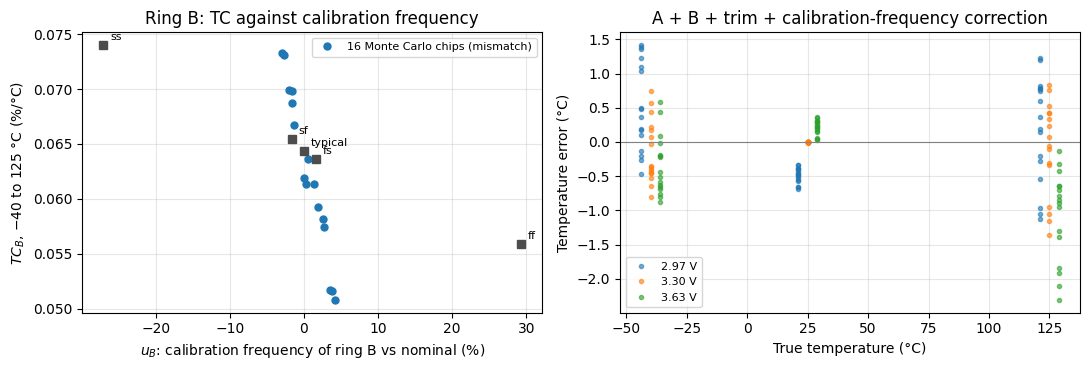

In [19]:
corner_u = np.log(cal.f_Hz_B / cal.loc["typical", "f_Hz_B"])
corner_tc = {c: 100 * np.log(d.set_index("temp_C").f_Hz_B[125] / d.set_index("temp_C").f_Hz_B[-40]) / 165
             for c, d in m[np.isclose(m.vdd_V, 3.30)].groupby("corner")}
print(f"correlation of TC_B with u_B over the Monte Carlo chips: {np.corrcoef(u_B, tc_B)[0, 1]:+.2f}")

mc["uB"] = mc.chip.map(u_B)
t_hat = (mc.eT_trim + mc.temp_C).to_numpy()
feat = mc.uB.to_numpy() * (t_hat - 25)
corrected = np.empty(len(mc))
for i in range(N_MC):
    tr = (mc.chip != i).to_numpy()
    c = (feat[tr] @ mc.eT_trim[tr]) / (feat[tr] @ feat[tr])
    corrected[~tr] = mc.eT_trim[~tr] - c * feat[~tr]
mc["eT_corr"] = corrected
ref = ref.assign(eT_corr=ref.eT_trim)
c_all = (feat @ mc.eT_trim) / (feat @ feat)
corr_table = pd.DataFrame({"A + B + supply trim": mc_row("eT_trim", False),
                           "   + calibration-frequency correction": mc_row("eT_corr", False)}).T.round(2)
try:
    display(corr_table)
except NameError:
    print(corr_table.to_string())
print(f"c fitted on all {N_MC} chips: {c_all:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(100 * u_B, tc_B, "o", ms=5, label=f"{N_MC} Monte Carlo chips (mismatch)")
for c in CORNERS:
    axes[0].plot(100 * corner_u[c], corner_tc[c], "s", color="0.3", ms=6)
    axes[0].annotate(c, (100 * corner_u[c], corner_tc[c]), textcoords="offset points", xytext=(5, 4), fontsize=8)
axes[0].set_xlabel("$u_B$: calibration frequency of ring B vs nominal (%)")
axes[0].set_ylabel("$TC_B$, −40 to 125 °C (%/°C)")
axes[0].set_title("Ring B: TC against calibration frequency")
axes[0].legend(fontsize=8)
for k, v in enumerate(VDDS):
    d = mc[np.isclose(mc.vdd_V, v)]
    axes[1].plot(d.temp_C + 4 * (k - 1), d.eT_corr, "o", ms=3, alpha=0.6, label=f"{v:.2f} V")
axes[1].axhline(0, color="0.5", lw=0.8)
axes[1].set_title("A + B + trim + calibration-frequency correction")
axes[1].set_xlabel("True temperature (°C)")
axes[1].set_ylabel("Temperature error (°C)")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

### 7.7 Interpretation

**Mismatch barely touches ring A but dominates the two-ring read-out.** Over 16 chips, ring A alone at nominal supply
keeps a 3σ spread of 0.33 °C: its 22 devices contribute independently and average out (frequency spread 0.22 %), and
the ratio calibration removes the common offset. The two-ring read-out spreads ±8.0 °C (3σ; worst chip 5.4 °C), and
almost all of it comes from ring B: with ring B nominal, ring A's mismatch gives only 0.43 °C. This error is random
from chip to chip and adds to the systematic corner residual of 7.3. With 16 chips, the 3σ figures carry about ±20 %
statistical uncertainty.

**The culprit is the mirror reference shared by all stages.** Ring B's frequency spreads 2.4 % and its TC 12 %
(0.0074 of 0.062 %/°C). The one-sigma shifts of 7.6 account for all of it (root-sum-square 0.0073 %/°C): MNB, the
nMOS diode whose gate voltage sets MNM and every nMOS starving device, gives about 73 % of the variance, and MNM, which
copies $I_B$ into the pMOS side, about 22 %. The 11 per-stage devices average out. An offset $\Delta V$ between MNB and
the devices that copy it changes their current by about $2\Delta V/V_{ov}$; the 2.1 % for 3.8 mV implies
$V_{ov} \approx 0.36$ V. At constant current $V_{ov}$ grows with temperature as mobility falls, so the relative error
shrinks when hot: one offset changes both the frequency at 25 °C and the TC, which is why they correlate at −0.98.

**Three ways out.** Mismatch falls as $1/\sqrt{WL}$, so making MNB and MNM 16 times larger (8/4 µm instead of 2/1)
should cut their offsets four times; section 7.8 tests it. A second calibration temperature measures each chip's TC directly, which is what
the best measured sensors of section 10 do. The third option needs neither hardware nor test time: ring B's calibration
frequency, already measured, predicts the error, and one coefficient fitted on the other chips brings the spread from
±8.0 to ±2.4 °C (3σ) and the worst chip from 5.4 to 2.3 °C. Its limit is visible in the left plot: the process corners
lie on a line about ten times flatter (ff runs 34 % faster with a TC only 13 % lower), because process mostly scales
the current by a common factor, which the ratio calibration already removes. The absolute frequency mixes process and
mismatch, so a usable correction has to separate them, for example with ring A's calibration frequency, which follows
process (+19 % in ff) but hardly mismatch (0.22 %). Training such a model needs a Monte Carlo with global variation
and mismatch together (section 14).

### 7.8 A fix to verify: larger mirror reference

Section 7.6 points at MNB and MNM, the two mirror devices shared by every stage. Mismatch falls as $1/\sqrt{WL}$, so
this section repeats the Monte Carlo with MNB and MNM at 8/4 µm instead of 2/1: the same $W/L$, 16 times the area,
so their $V_{TH}$ spread should fall four times. The 11 MNS keep 2/1 µm. They matter less, because their offsets
average over the stages, and making them long-channel as well would remove most of their channel-length modulation,
which is part of ring B's supply sensitivity: the five simulations at the end of the next cell show $S_{V,B}$ falling
from about 20 to 8 %/V in that case, and in a trial Monte Carlo (not repeated here) the per-chip trim ratio
$v_A/v_B$ became so noisy that the read-out spread grew instead.

The variant gets its own read-out fit on its typical corner (21 points) and then the same 16 chips (same seeds, so
the same random draws scaled to the new sizes), each with its own calibration and supply trim; ring A is unchanged and
reuses the Monte Carlo of 7.5. 170 simulations of ring B, cached in a CSV file. Only the
typical corner is simulated for the variant: its process corners and its layout are not repeated here.

In [20]:
FIX = {"wmir": 8.0, "lmir": 4.0}                  # MNB and MNM; the MNS keep 2/1
CSV_FIX = os.path.join(WORK, f"fix_mirror_{FIX['wmir']:g}x{FIX['lmir']:g}_{N_MC}.csv")
fix_jobs = ([("grid", -1, t, v) for t in TEMPS for v in VDDS]
            + [("mc", c, t, v) for c in range(N_MC) for t in MC_TEMPS for v in VDDS])


def fix_point(job):
    kind, chip, temp, vdd = job
    r = run_csro(bias=B_BIAS, temp=temp, vdd=vdd, mc_seed=None if chip < 0 else 2000 + chip, t_stop=0.9e-6, **FIX)
    return {"kind": kind, "chip": chip, "temp_C": temp, "vdd_V": vdd, "f_Hz": r["f"]}


fix_raw = pd.read_csv(CSV_FIX) if (os.path.exists(CSV_FIX) and not RERUN) else None
if fix_raw is not None and len(fix_raw) == len(fix_jobs):
    print(f"loaded {len(fix_raw)} simulations from {CSV_FIX}")
else:
    t0, rows = time.time(), []
    with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
        for i, row in enumerate(ex.map(fix_point, fix_jobs), 1):
            rows.append(row)
            if i % 33 == 0 or i == len(fix_jobs):
                print(f"{i}/{len(fix_jobs)} simulations ({time.time() - t0:.0f} s)", flush=True)
    fix_raw = pd.DataFrame(rows)
    fix_raw.to_csv(CSV_FIX, index=False)
    print("saved", CSV_FIX)

# the alternative: all 13 nMOS mirror devices (MNB, MNM and the MNS) at 8/4
alt = {k: run_csro(bias=B_BIAS, temp=t, vdd=v, t_stop=0.9e-6, wmir=8.0, lmir=4.0, wmns=8.0, lmns=4.0)["f"]
       for k, (t, v) in {"f0": (25, 3.30), "t0": (0, 3.30), "t55": (55, 3.30), "vm": (25, 2.97), "vp": (25, 3.63)}.items()}
print(f"all 13 nMOS mirror devices at 8/4: TC = {100 * (alt['t55'] - alt['t0']) / 55 / alt['f0']:.3f} %/C, "
      f"S_V = {100 * (alt['vp'] - alt['vm']) / 0.66 / alt['f0']:.1f} %/V")

33/165 simulations (199 s)
66/165 simulations (382 s)
99/165 simulations (581 s)
132/165 simulations (766 s)
165/165 simulations (968 s)
saved /content/gf180_work/fix_mirror_8x4_16.csv
all 13 nMOS mirror devices at 8/4: TC = 0.100 %/C, S_V = 8.4 %/V


,TC_B (%/C),"S_V,B (%/V)",cond(S),sigma TC_B (%/C),sigma f_B at 25 C (%),max |mean| (C),max 3 sigma (C),worst chip (C)
nMOS mirror devices,,,,,,,,
2/1 (design),0.0706,20.5402,2.0348,0.0074,2.4084,1.5546,8.0229,5.3926
+ calibration-frequency correction,NaN,NaN,NaN,NaN,NaN,1.0764,2.3558,2.3094
"MNB, MNM 8/4 (fix)",0.1204,21.7962,1.8716,0.0028,0.9550,1.2996,2.4001,2.3459
+ calibration-frequency correction,NaN,NaN,NaN,NaN,NaN,1.1999,2.2387,2.4607


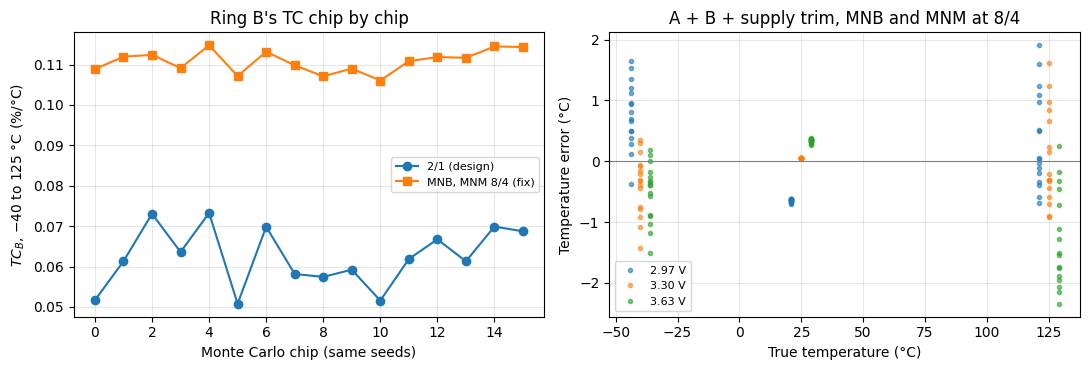

In [21]:
fx = fix_raw.assign(vdd_V=fix_raw.vdd_V.round(2))

# read-out fit for the variant, on its typical corner (ring A: the typical grid of section 6)
gB = fx[fx.kind == "grid"].set_index(["temp_C", "vdd_V"]).f_Hz
tA_pts = m[typ_rows].assign(vdd_V=m.vdd_V.round(2)).set_index(["temp_C", "vdd_V"])
gfit = pd.DataFrame({"xA": tA_pts.xA, "xB": np.log(gB / gB[(25, 3.30)])}).dropna()
k_fix_typ = ((gfit.xA[(25, 3.63)] - gfit.xA[(25, 2.97)]) / (gfit.xB[(25, 3.63)] - gfit.xB[(25, 2.97)]))
gfit = gfit.reset_index()
coef_fix = np.linalg.lstsq(basis_trim((gfit.xA - k_fix_typ * gfit.xB).to_numpy(), gfit.xB.to_numpy()),
                           gfit.temp_C.to_numpy(), rcond=None)[0]


def grid_sens(f):
    # TC (0 to 55 C) and S_V (2.97 to 3.63 V) around 25 C / 3.3 V from a typical grid, both relative to f(25, 3.3)
    return ((f[(55, 3.30)] - f[(0, 3.30)]) / 55 / f[(25, 3.30)], (f[(25, 3.63)] - f[(25, 2.97)]) / 0.66 / f[(25, 3.30)])


def typ_grid(df):
    d = df[df.corner == "typical"]
    return d.assign(vdd_V=d.vdd_V.round(2)).set_index(["temp_C", "vdd_V"]).f_Hz


tA_g, vA_g = grid_sens(typ_grid(pvt))
tc_des, sv_des = grid_sens(typ_grid(pvt_b))
tc_fix, sv_fix = grid_sens(gB)

# the same 16 chips: ring A from 7.5, ring B with the larger mirror devices
mf = (fx[fx.kind == "mc"].rename(columns={"f_Hz": "f_B"})[["chip", "temp_C", "vdd_V", "f_B"]]
      .merge(mc[["chip", "temp_C", "vdd_V", "f_A", "xA"]], on=["chip", "temp_C", "vdd_V"]))
calB = mf[(mf.temp_C == 25) & np.isclose(mf.vdd_V, 3.30)].set_index("chip").f_B
mf["xB"] = np.log(mf.f_B / mf.chip.map(calB))
s25f = mf[mf.temp_C == 25].sort_values("vdd_V")
vB_fix = s25f.groupby("chip").xB.apply(lambda x: (x.iloc[-1] - x.iloc[0]) / 0.66)
mf["eT_fix"] = (basis_trim((mf.xA - mf.chip.map(vA_mc / vB_fix) * mf.xB).to_numpy(), mf.xB.to_numpy()) @ coef_fix
                - mf.temp_C)
xb33f = mf[np.isclose(mf.vdd_V, 3.30)].pivot(index="chip", columns="temp_C", values="xB")
tc_B_fix = 100 * (xb33f[125] - xb33f[-40]) / 165

# calibration-frequency correction (leave-one-chip-out), as in 7.6
u_fix = np.log(calB / gB[(25, 3.30)])
feat_f = mf.chip.map(u_fix).to_numpy() * (mf.eT_fix + mf.temp_C - 25).to_numpy()
corr_f = np.empty(len(mf))
for i in range(N_MC):
    tr = (mf.chip != i).to_numpy()
    c = (feat_f[tr] @ mf.eT_fix[tr]) / (feat_f[tr] @ feat_f[tr])
    corr_f[~tr] = mf.eT_fix[~tr] - c * feat_f[~tr]
mf["eT_fix_corr"] = corr_f


def spread(d, col):
    per_point = d.groupby(["temp_C", "vdd_V"])[col]
    return per_point.mean().abs().max(), 3 * per_point.std().max(), d[col].abs().max()


rows = []
for name, d, col, tc, sv, tcs, fsd in (
        ("2/1 (design)", mc, "eT_trim", tc_des, sv_des, tc_B, cal_mc.f_B),
        ("   + calibration-frequency correction", mc, "eT_corr", np.nan, np.nan, None, None),
        ("MNB, MNM 8/4 (fix)", mf, "eT_fix", tc_fix, sv_fix, tc_B_fix, calB),
        ("   + calibration-frequency correction", mf, "eT_fix_corr", np.nan, np.nan, None, None)):
    mean, s3, worst = spread(d, col)
    rows.append({"nMOS mirror devices": name, "TC_B (%/C)": 100 * tc, "S_V,B (%/V)": 100 * sv,
                 "cond(S)": np.linalg.cond(np.array([[tA_g, vA_g], [tc, sv]]) * RANGES) if tc == tc else np.nan,
                 "sigma TC_B (%/C)": tcs.std() if tcs is not None else np.nan,
                 "sigma f_B at 25 C (%)": 100 * fsd.std() / fsd.mean() if fsd is not None else np.nan,
                 "max |mean| (C)": mean, "max 3 sigma (C)": s3, "worst chip (C)": worst})
fix_table = pd.DataFrame(rows).set_index("nMOS mirror devices").round(4)
try:
    display(fix_table)
except NameError:
    print(fix_table.to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(tc_B.index, tc_B, "o-", label="2/1 (design)")
axes[0].plot(tc_B_fix.index, tc_B_fix, "s-", label="MNB, MNM 8/4 (fix)")
axes[0].set_xlabel("Monte Carlo chip (same seeds)")
axes[0].set_ylabel("$TC_B$, −40 to 125 °C (%/°C)")
axes[0].set_title("Ring B's TC chip by chip")
axes[0].legend(fontsize=8)
for k, v in enumerate(VDDS):
    d = mf[np.isclose(mf.vdd_V, v)]
    axes[1].plot(d.temp_C + 4 * (k - 1), d.eT_fix, "o", ms=3, alpha=0.6, label=f"{v:.2f} V")
axes[1].axhline(0, color="0.5", lw=0.8)
axes[1].set_title("A + B + supply trim, MNB and MNM at 8/4")
axes[1].set_xlabel("True temperature (°C)")
axes[1].set_ylabel("Temperature error (°C)")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

**The fix works where the diagnosis said it would.** With MNB and MNM 16 times larger, ring B's frequency spread
falls from 2.4 to 0.96 % and its TC spread from 0.0074 to 0.0028 %/°C, close to the threefold reduction expected when
the two devices that carried 95 % of the variance get four times smaller offsets and the rest (MPB and the per-stage
devices) stays as it was. The two-ring read-out follows: ±2.4 °C (3σ) instead of ±8.0 °C, and
2.3 °C instead of 5.4 °C for the worst chip, with a new read-out fit and nothing else changed. The cost is about
60 µm² of extra area, 4 % of ring B. With the mismatch error now at the level of the corner residual, the
calibration-frequency correction of 7.6 adds little on top (2.2 °C).

**It also changes the nominal design.** TC_B rises from 0.071 to 0.120 %/°C while $S_{V,B}$ stays near 22 %/V, so the
pair is slightly better conditioned (1.9 instead of 2.0). The likely reason is that MNB and the MNS no longer have
the same length, so the copy ratio of the mirror now depends on temperature through their different threshold
voltages.

**Why not all 13 devices.** Making the MNS long-channel too keeps the TC benefit but drops $S_{V,B}$ to 8.4 %/V (last
line of the first cell), because part of ring B's supply sensitivity comes from the channel-length modulation of its
short starving devices. The trim ratio $v_A/v_B$ then carries the remaining spread of $v_B$, now relatively larger, and
multiplies it by a larger $v_A/v_B$; in the trial run the read-out got worse instead of better. A fix has to be
checked against every quantity the read-out uses, not only the one it targets.

**Caveat.** The variant is characterized on the typical corner only. Because MNB and the MNS now differ in length,
the copy ratio may also depend on process, so the corner study of 7.3 and the layout of section 9 would have to be
repeated before adopting it.

## 8. Aging

Bias-temperature instability (BTI) raises $|V_{TH}|$ over the lifetime of a chip. In a SiO₂-gate process such as
this one, NBTI on the pMOS devices is usually the dominant mechanism. It is modelled here with the `dvp` / `dvn`
knobs of section 4: a DC source in series with each inverter gate, so the device sees its gate voltage shifted by
$\Delta V_{TH}$ without any change in capacitance. Two scenarios, both from 0 to 50 mV:

- **NBTI**: pMOS only (`dvp = ΔV_TH`, `dvn = 0`).
- **Both**: pMOS and nMOS shifted by the same amount.

Only the inverter devices of both rings are aged. The starving, mirror and stack devices of ring B sit under DC
stress; the mirror pairs (MPB/MPS and MNB/MNS) share the same $V_{GS}$ and would age together, keeping the mirror
ratio, but a shift in the stack (MPD/MNB) would change $I_B$ and is not modelled here.

### 8.1 Frequency shift versus ΔV<sub>TH</sub>

Typical corner, 25 °C, 3.3 V; 24 simulations.

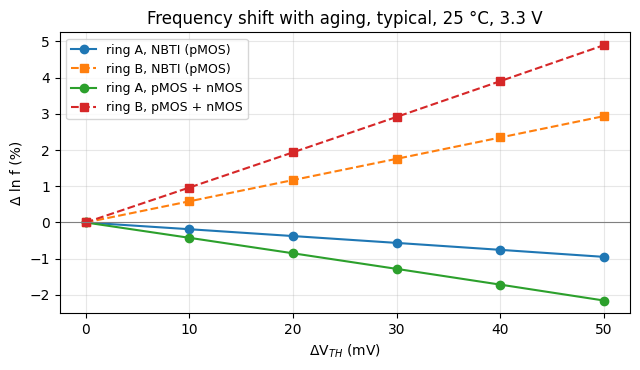

,ring A: %/10 mV,ring B: %/10 mV
scenario,,
NBTI (pMOS),-0.190,0.587
pMOS + nMOS,-0.431,0.980


In [22]:
AGE_MV = [0, 10, 20, 30, 40, 50]
SCENARIOS = {"NBTI (pMOS)": lambda dv: {"dvp": dv, "dvn": 0.0},
             "pMOS + nMOS": lambda dv: {"dvp": dv, "dvn": dv}}
RINGS = {"A": run_ro, "B": lambda **kw: run_csro(bias=B_BIAS, **kw)}


def age_point(job):
    scen, mv, ring = job
    r = RINGS[ring](temp=25, vdd=3.30, **SCENARIOS[scen](mv * 1e-3))
    return {"scenario": scen, "dVth_mV": mv, "ring": ring, "f_Hz": r["f"], "power_W": r["power"]}


age_jobs = [(s, mv, ring) for s in SCENARIOS for mv in AGE_MV for ring in RINGS]
with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
    aging = pd.DataFrame(list(ex.map(age_point, age_jobs)))
fresh = aging[aging.dVth_mV == 0].set_index(["scenario", "ring"]).f_Hz
aging["dlnf_pct"] = 100 * np.log(aging.f_Hz / [fresh[(s, r)] for s, r in zip(aging.scenario, aging.ring)])

fig, ax = plt.subplots(figsize=(6.5, 3.8))
for (scen, ring), d in aging.groupby(["scenario", "ring"]):
    ax.plot(d.dVth_mV, d.dlnf_pct, "o-" if ring == "A" else "s--", label=f"ring {ring}, {scen}")
ax.axhline(0, color="0.5", lw=0.8)
ax.set_xlabel("ΔV$_{TH}$ (mV)")
ax.set_ylabel("Δ ln f (%)")
ax.set_title("Frequency shift with aging, typical, 25 °C, 3.3 V")
ax.grid(alpha=0.3)
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

age_slope = (aging.groupby(["scenario", "ring"])[["dVth_mV", "dlnf_pct"]]
             .apply(lambda d: 10 * np.polyfit(d.dVth_mV, d.dlnf_pct, 1)[0])
             .unstack("ring").round(3))
age_slope.columns = [f"ring {c}: %/10 mV" for c in age_slope.columns]
try:
    display(age_slope)
except NameError:
    print(age_slope.to_string())

### 8.2 Why ring B speeds up

Ring A slows down, as expected: a higher $|V_{TH}|$ means less overdrive and less current. Ring B speeds up. Its
supply current is set by the bias network, not by the inverters, so the power stays the same; if the frequency rises
at constant current, each cycle must take less charge. The load and the swing do not change, so the charge saved is
the short-circuit charge that flows through MP and MN while both conduct during a transition: higher effective
thresholds shorten that overlap. The cell below checks the constant power and the charge per cycle, $Q = P/(V_{DD} f)$.

In [23]:
b_fresh = run_csro(bias=B_BIAS)
b_aged = run_csro(bias=B_BIAS, dvp=0.05)
mech = pd.DataFrame([{"ring B": name, "f (MHz)": r["f"] / 1e6, "P (uW)": r["power"] * 1e6,
                      "charge per cycle (pC)": r["power"] / (3.3 * r["f"]) * 1e12}
                     for name, r in (("fresh", b_fresh), ("NBTI, 50 mV", b_aged))]).set_index("ring B").round(4)
try:
    display(mech)
except NameError:
    print(mech.to_string())

,f (MHz),P (uW),charge per cycle (pC)
ring B,,,
fresh,46.9245,183.9898,1.1882
"NBTI, 50 mV",48.3218,184.0586,1.1542


### 8.3 What the temperature read-out sees

Two rings give two equations for three unknowns ($\Delta T$, $\Delta V_{DD}$, $\Delta V_{TH}$), so aging cannot be
separated; it is read as some combination of temperature and supply. Mapping the aging vector through $S^{-1}$
(section 7.1, typical corner) gives that combination per 10 mV of $\Delta V_{TH}$. The second table checks it with the
full read-out of section 7.3 on a typical chip calibrated fresh and aged afterwards (NBTI, 25 and 50 mV) at three
temperatures; 18 simulations.

In [24]:
S_typ = np.array([[tA, vA], [sens_b[(B_BIAS, "typical")][1], sens_b[(B_BIAS, "typical")][2]]])
rows = []
for scen in SCENARIOS:
    a = age_slope.loc[scen].to_numpy() / 100          # d ln f per 10 mV, rings A and B
    dT_ab, dV_ab = np.linalg.solve(S_typ, a)
    rows.append({"scenario": scen, "A alone: apparent dT (C)": a[0] / tA,
                 "A + B: apparent dT (C)": dT_ab, "A + B: apparent dV_DD (mV)": 1e3 * dV_ab})
equiv = pd.DataFrame(rows).set_index("scenario").round(2)
equiv.columns.name = "per 10 mV of dV_TH"
try:
    display(equiv)
except NameError:
    print(equiv.to_string())

# full read-out on an aged typical chip, calibrated when fresh (coefficients coef_a, coef_t from 7.5)
k_typ = (v_A / v_B)["typical"]


def aged_readout(job):
    temp, mv = job
    fa = run_ro(temp=temp, vdd=3.30, dvp=mv * 1e-3)["f"]
    fb = run_csro(bias=B_BIAS, temp=temp, vdd=3.30, dvp=mv * 1e-3)["f"]
    xa = np.log(fa / cal.loc["typical", "f_Hz_A"])
    xb = np.log(fb / cal.loc["typical", "f_Hz_B"])
    t_a = (basis_a(np.array([xa])) @ coef_a)[0]
    t_ab = (basis_trim(np.array([xa - k_typ * xb]), np.array([xb])) @ coef_t)[0]
    return {"T (C)": temp, "NBTI dV_TH (mV)": mv, "A alone: error (C)": t_a - temp,
            "A + B + trim: error (C)": t_ab - temp}


with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
    aged = pd.DataFrame(list(ex.map(aged_readout, [(t, mv) for t in (-40, 25, 125) for mv in (0, 25, 50)])))
aged = aged.round(2)
try:
    display(aged)
except NameError:
    print(aged.to_string())

per 10 mV of dV_TH,A alone: apparent dT (C),A + B: apparent dT (C),A + B: apparent dV_DD (mV)
scenario,,,
NBTI (pMOS),1.00,3.12,17.99
pMOS + nMOS,2.28,5.63,28.53


,T (C),NBTI dV_TH (mV),A alone: error (C),A + B + trim: error (C)
0,-40,0,0.11,-0.23
1,-40,25,2.24,6.37
2,-40,50,4.44,13.25
3,25,0,-0.03,-0.01
4,25,25,2.47,7.98
5,25,50,5.05,16.37
6,125,0,-0.10,0.14
7,125,25,2.83,10.94
8,125,50,5.83,22.29


### 8.4 Interpretation

**The two rings age in opposite directions because different things set their frequency.** In ring A the inverter
devices set the current, so a higher $|V_{TH}|$ means less overdrive and a slower ring: −0.19 %/10 mV with NBTI
only, −0.43 %/10 mV when both devices shift. In ring B the bias network sets the current and the inverters only
steer it. Aging leaves the power unchanged (184.0 vs 184.1 µW) while the charge per cycle drops from 1.188 to
1.154 pC (−2.9 %). The saved charge is short-circuit charge: higher thresholds shorten the time MP and MN conduct
together during each transition, so more of the bias current reaches the load and the ring speeds up
(+0.59 %/10 mV with NBTI, +0.98 %/10 mV with both). The sign of each response comes from this mechanism, not from
which device ages faster: both scenarios give the same signs.

**Ring B trades supply robustness for aging sensitivity.** Read as a temperature, 10 mV of NBTI looks like +1.0 °C
for ring A alone but +3.1 °C (and +18 mV of supply) for the A + B read-out, because ring B's large aging response is
folded into the inversion. The balance still favours A + B: ring A alone carries about ±41 °C from a ±10 % supply,
while A + B starts from 1–5 °C across corners and adds about 3.1 °C per 10 mV. A + B stays better up to roughly
170 mV of NBTI, but aging becomes its dominant error beyond about 15 mV.

**Aging needs a third observable.** Two rings give two equations for three unknowns ($\Delta T$, $\Delta V_{DD}$,
$\Delta V_{TH}$), so aging can only appear as a hidden error. A third ring that sees the same temperature and supply
but does not age, for example a copy of ring A powered only during each measurement, would make aging observable:
the difference between the stressed and the unstressed copy isolates $\Delta V_{TH}$. Its evolution over time is
exactly the kind of signal an aging-prediction model would learn from.

## 9. Layout and post-layout simulation

Both rings are laid out as code. The Python cells below write a magic script that paints every rectangle (wells,
diffusions, poly, contacts, metal 1 and 2) on the GF180MCU grid, with the same W/L as the schematics; magic checks the
GF180 design rules and extracts the circuit with its junction areas and wiring capacitance, and netgen compares the
extracted netlist with the schematic (LVS). The extracted netlists then replace the schematics in ngspice.

Tools: magic 8.3.464, netgen 1.5.272 and the `gf180mcuC` technology files of open_pdks 1.0.471 (conda packages from
the litex-hub channel, installed with micromamba).

In [25]:
MAMBA = os.path.join(WORK, "micromamba", "bin", "micromamba")
LENV = os.path.join(WORK, "layout_env")
LAYOUT_PKGS = ["litex-hub::magic=8.3.464_0_gcb73ebf", "litex-hub::netgen=1.5.272_0_g178af5f",
               "litex-hub::open_pdks.gf180mcuc=1.0.471_1_gd8bfd6f"]
if not os.path.exists(os.path.join(LENV, "bin", "netgen")):
    if not os.path.exists(MAMBA):
        sh("downloading micromamba 2.3.0", f"mkdir -p {WORK}/micromamba && cd {WORK}/micromamba && "
           "curl -sSL -o mm.tar.bz2 https://conda.anaconda.org/conda-forge/linux-64/micromamba-2.3.0-0.tar.bz2 && "
           "tar -xjf mm.tar.bz2 bin/micromamba")
    sh("installing magic, netgen and the gf180mcuC PDK files",
       f"MAMBA_ROOT_PREFIX={WORK}/mamba {MAMBA} create -y -q -p {LENV} -c litex-hub -c conda-forge "
       + " ".join(f'"{p}"' for p in LAYOUT_PKGS))
PDK_ROOT = os.path.join(LENV, "share", "pdk")
MAGICRC = os.path.join(PDK_ROOT, "gf180mcuC", "libs.tech", "magic", "gf180mcuC.magicrc")
NETGEN_SETUP = os.path.join(PDK_ROOT, "gf180mcuC", "libs.tech", "netgen", "gf180mcuC_setup.tcl")
LAYOUT = os.path.join(WORK, "layout")
os.makedirs(LAYOUT, exist_ok=True)
print(subprocess.run([os.path.join(LENV, "bin", "magic"), "--version"], capture_output=True, text=True).stdout.strip(),
      "| PDK files:", os.path.isfile(MAGICRC) and os.path.isfile(NETGEN_SETUP))

downloading micromamba 2.3.0 ...
installing magic, netgen and the gf180mcuC PDK files ...
8.3.464 | PDK files: True


### 9.1 Layout generators

**Ring A** (2.1 µm per stage): each stage has its nMOS above the VSS rail and its pMOS below the VDD rail, sharing
one vertical poly gate; the input reaches the gate through a poly contact between the two devices, the drains are
joined by a metal-1 strip that is also the output, and the output runs straight into the next stage's input. Substrate
and n-well taps sit under the rails, and the feedback from the last stage to the first runs in metal 2 below the VSS
rail.

**Ring B** (5.6 µm per stage): the starving devices are turned sideways, so that two horizontal poly lines are the
gates of all of them: `nb` for the 11 MNS and `pb` for the 11 MPS. The bias devices sit at the start of the same
rows, MNB and MPB as diodes on those lines and MNM in a column of its own. MPD has its own n-well, tied to `nd`, and
the 70 µm resistor runs underneath the row, from `nd` to VDD.

In [26]:
class Painter:
    # collects magic commands; coordinates in um
    def __init__(self):
        self.cmds = []

    def rect(self, layer, x1, y1, x2, y2):
        self.cmds.append(f"box {min(x1, x2):.3f}um {min(y1, y2):.3f}um {max(x1, x2):.3f}um {max(y1, y2):.3f}um\n"
                         f"paint {layer}")

    def label(self, text, x1, y1, x2, y2, port=None):
        self.cmds.append(f"box {x1:.3f}um {y1:.3f}um {x2:.3f}um {y2:.3f}um\nlabel {text} c metal1")
        if port is not None:
            self.cmds.append(f"port make {port}")

    def via(self, x, y):                                  # via1 with metal-1 and metal-2 landing pads
        self.rect("m1", x - 0.25, y - 0.25, x + 0.25, y + 0.25)
        self.rect("m2", x - 0.25, y - 0.25, x + 0.25, y + 0.25)
        self.rect("via1", x - 0.13, y - 0.13, x + 0.13, y + 0.13)


def inverter_core(p, x0, y_n, y_p, wn=1.0, wp=2.5):
    # nMOS (W = wn) from y_n, pMOS (W = wp) from y_p, L = 0.28, shared gate, input pad between them
    gap_top = y_n + wn
    p.rect("ndiff", x0 - 0.58, y_n, x0 + 0.58, y_n + wn)
    p.rect("pdiff", x0 - 0.58, y_p, x0 + 0.58, y_p + wp)
    p.rect("poly", x0 - 0.14, y_n - 0.22, x0 + 0.14, y_p + wp + 0.22)
    for x1 in (-0.515, 0.285):
        p.rect("ndc", x0 + x1, y_n + 0.065, x0 + x1 + 0.23, y_n + wn - 0.065)
        p.rect("pdc", x0 + x1, y_p + 0.065, x0 + x1 + 0.23, y_p + wp - 0.065)
    yi = gap_top + 0.42                                   # input poly pad and contact
    p.rect("poly", x0 - 0.565, yi, x0 - 0.14, yi + 0.36)
    p.rect("pc", x0 - 0.50, yi + 0.065, x0 - 0.27, yi + 0.295)
    p.rect("m1", x0 - 0.555, yi + 0.065, x0 - 0.215, yi + 0.295)
    p.rect("m1", x0 + 0.285, y_n + 0.01, x0 + 0.515, y_p + wp - 0.01)     # drains: output
    return yi + 0.065, yi + 0.295                         # y range of the input / output metal


def ring_a_layout(n=11, pitch=2.1):
    p, h = Painter(), pitch / 2
    for i in range(n):
        x0 = i * pitch
        p.rect("pwell", x0 - h, -0.40, x0 + h, 2.14)      # wells before diffusions
        p.rect("nwell", x0 - h, 2.47, x0 + h, 6.70)
        p.rect("psd", x0 - h, -0.20, x0 + h, 0.20)        # substrate tap under VSS
        p.rect("psc", x0 - 0.6, -0.115, x0 + 0.6, 0.115)
        p.rect("nsd", x0 - h + 0.15, 6.00, x0 + h - 0.15, 6.40)   # n-well tap under VDD
        p.rect("nsc", x0 - 0.6, 6.085, x0 + 0.6, 6.315)
        p.rect("m1", x0 - h, -0.30, x0 + h, 0.30)
        p.rect("m1", x0 - h, 5.90, x0 + h, 6.50)
        y1, y2 = inverter_core(p, x0, 0.80, 2.90)
        p.rect("m1", x0 - 0.515, 0.30, x0 - 0.285, 1.79)  # sources to the rails
        p.rect("m1", x0 - 0.515, 2.91, x0 - 0.285, 5.90)
        p.rect("m1", x0 - h, y1, x0 - 0.215, y2)          # input from the left edge
        if i < n - 1:
            p.rect("m1", x0 + 0.515, y1, x0 + h, y2)      # output to the next stage
        p.label(f"n{i}", x0 - 0.555, y1, x0 - 0.215, y2)
    xe, xs = (n - 1) * pitch + h + 0.8, -h - 0.8          # feedback in metal 2 below the VSS rail
    p.rect("m1", (n - 1) * pitch + 0.515, y1, xe + 0.25, y2)
    p.rect("m1", xs - 0.25, y1, -h, y2)
    for xv in (xe, xs):
        p.via(xv, (y1 + y2) / 2)
        p.rect("m2", xv - 0.20, -1.30, xv + 0.20, (y1 + y2) / 2)
    p.rect("m2", xs - 0.20, -1.30, xe + 0.20, -0.90)
    p.label("VDD", -h, 5.90, -h + 0.5, 6.50, port=1)
    p.label("VSS", -h, -0.30, -h + 0.5, 0.30, port=2)
    return p.cmds


def ring_b_layout(n=11, pitch=5.6, r_len=70.0):
    p = Painter()
    xb1, xb2, xl = -2 * pitch, -pitch, (n - 1) * pitch    # bias columns, last stage
    x0r, x1r = xb1 - 3.2, xl + 3.2                        # row extent
    p.rect("pwell", x0r, -0.40, x1r, 4.84)
    p.rect("nwell", x0r, 5.17, x1r, 12.0)
    p.rect("psd", x0r, -0.20, x1r, 0.20)
    p.rect("nsd", x0r + 0.15, 11.30, x1r - 0.15, 11.70)
    for xc in [xb1, xb2] + [i * pitch for i in range(n)]:
        p.rect("psc", xc - 2.2, -0.115, xc + 2.2, 0.115)
        p.rect("nsc", xc - 2.2, 11.385, xc + 2.2, 11.615)
    p.rect("m1", x0r, -0.30, x1r, 0.30)                   # VSS
    p.rect("m1", x0r, 11.20, x1r + 3.7, 11.80)            # VDD, extended to the resistor
    p.rect("poly", xb1 - 1.45, 1.40, x1r - 0.35, 2.40)    # nb: gates of MNB, MNM and the 11 MNS (L = 1)
    p.rect("poly", xb1 - 2.95, 9.30, x1r - 0.25, 10.30)   # pb: gates of MPB and the 11 MPS (L = 1)

    def nstarve(x0):                                      # W = 2 nMOS on the nb line, source to VSS
        p.rect("ndiff", x0 - 1.0, 0.80, x0 + 1.0, 3.00)
        p.rect("ndc", x0 - 0.935, 0.865, x0 + 0.935, 1.095)
        p.rect("ndc", x0 - 0.935, 2.705, x0 + 0.935, 2.935)
        p.rect("m1", x0 - 0.935, 0.30, x0 + 0.935, 1.15)
        p.rect("m1", x0 - 0.935, 2.65, x0 + 0.935, 2.99)  # drain bar

    def pstarve(x0):                                      # W = 5 pMOS on the pb line, source to VDD
        p.rect("pdiff", x0 - 2.5, 8.70, x0 + 2.5, 10.90)
        p.rect("pdc", x0 - 2.435, 8.765, x0 + 2.435, 8.995)
        p.rect("pdc", x0 - 2.435, 10.605, x0 + 2.435, 10.835)
        p.rect("m1", x0 - 2.435, 8.71, x0 + 2.435, 9.05)  # drain bar
        p.rect("m1", x0 - 2.435, 10.55, x0 + 2.435, 11.20)

    for i in range(n):
        x0 = i * pitch
        nstarve(x0)
        pstarve(x0)
        y1, y2 = inverter_core(p, x0, 3.50, 5.60)
        p.rect("m1", x0 - 0.515, 2.65, x0 - 0.285, 4.49) # MN source to the MNS drain
        p.rect("m1", x0 - 0.515, 5.61, x0 - 0.285, 8.71) # MP source to the MPS drain
        p.rect("m1", x0 - (2.0 if i == 0 else pitch / 2), y1, x0 - 0.215, y2)
        p.rect("m1", x0 + 0.515, y1, x0 + (2.0 if i == n - 1 else pitch / 2), y2)
        p.label(f"n{i}", x0 - 0.555, y1, x0 - 0.215, y2)
    for xv in (-2.25, xl + 2.25):                         # feedback in metal 2 below the VSS rail
        p.via(xv, (y1 + y2) / 2)
        p.rect("m2", xv - 0.2, -1.6, xv + 0.2, (y1 + y2) / 2)
    p.rect("m2", -2.45, -1.6, xl + 2.45, -1.2)
    # bias column 1: MNB (diode on nb) and MPB (diode on pb)
    nstarve(xb1)
    p.rect("m1", xb1 + 0.935, 2.65, xb1 + 1.67, 2.99)
    p.rect("m1", xb1 + 1.33, 1.05, xb1 + 1.67, 2.99)
    p.rect("pc", xb1 + 1.385, 1.785, xb1 + 1.615, 2.015)
    p.via(xb1 + 1.5, 1.30)
    pstarve(xb1)
    p.rect("m1", xb1 + 2.435, 8.71, xb1 + 3.07, 9.05)
    p.rect("m1", xb1 + 2.73, 8.71, xb1 + 3.07, 9.97)
    p.rect("pc", xb1 + 2.785, 9.685, xb1 + 3.015, 9.915)
    p.label("nb", xb1 + 1.33, 2.2, xb1 + 1.67, 2.5)
    p.label("pb", xb1 + 2.73, 9.3, xb1 + 3.07, 9.6)
    # bias column 2: MNM (gate nb, drain to pb)
    nstarve(xb2)
    p.rect("m1", xb2 - 0.17, 2.65, xb2 + 0.17, 9.97)
    p.rect("pc", xb2 - 0.115, 9.685, xb2 + 0.115, 9.915)
    # below the row: MPD in its own n-well (body = source = nd), then R from nd to VDD
    xm = xb1 - 2.0
    p.rect("nwell", xm - 2.95, -9.00, xm + 3.40, -5.37)
    p.rect("nsd", xm - 2.4, -8.85, xm + 2.4, -8.45)
    p.rect("nsc", xm - 2.2, -8.765, xm + 2.2, -8.535)
    p.rect("pdiff", xm - 2.5, -8.00, xm + 2.5, -5.80)
    p.rect("pdc", xm - 2.435, -7.935, xm + 2.435, -7.705)
    p.rect("pdc", xm - 2.435, -6.095, xm + 2.435, -5.865)
    p.rect("poly", xm - 2.75, -7.40, xm + 3.10, -6.40)
    p.rect("pc", xm + 2.785, -7.015, xm + 3.015, -6.785)
    p.rect("m1", xm - 2.435, -8.82, xm + 2.435, -7.65)    # tap + source: nd
    xr = -8.0                                             # left end of the resistor
    p.rect("m1", xm + 2.435, -7.99, xr - 0.315, -7.65)
    p.rect("m1", xm - 2.435, -6.15, xb1 + 1.75, -5.81)    # drain bar: nb
    p.rect("m1", xm + 2.73, -7.07, xm + 3.07, -5.81)      # gate to drain
    p.via(xb1 + 1.5, -5.90)
    p.rect("m2", xb1 + 1.30, -5.90, xb1 + 1.70, 1.30)     # nb up to MNB
    p.rect("hires", xr, -4.5, xr + r_len, -3.5)           # R: r_len x 1 um of ppolyf_u_1k
    p.rect("poly", xr - 0.61, -4.5, xr, -3.5)
    p.rect("poly", xr + r_len, -4.5, xr + r_len + 0.61, -3.5)
    p.rect("pc", xr - 0.545, -4.435, xr - 0.315, -3.565)
    p.rect("pc", xr + r_len + 0.315, -4.435, xr + r_len + 0.545, -3.565)
    p.rect("m1", xr - 0.545, -7.99, xr - 0.315, -3.51)
    p.rect("m1", xr + r_len + 0.315, -4.49, xr + r_len + 0.545, -3.51)
    xv = xr + r_len + 0.43
    p.via(xv, -4.0)
    p.rect("m2", xv - 0.2, -4.0, xv + 0.2, 11.5)
    p.via(xv, 11.5)
    p.label("nd", xr - 0.545, -6.0, xr - 0.315, -5.5)
    p.label("VDD", x0r, 11.2, x0r + 0.5, 11.8, port=1)
    p.label("VSS", x0r, -0.3, x0r + 0.5, 0.3, port=2)
    return p.cmds


def run_magic(cell, cmds):
    # paints the cell, runs DRC, writes .mag / .gds and two netlists: devices only (LVS) and devices + capacitances
    with open(os.path.join(LAYOUT, f"{cell}_paint.tcl"), "w") as f:
        f.write("\n".join(cmds) + "\n")
    script = textwrap.dedent(f'''\
        cellname rename (UNNAMED) {cell}
        load {cell}
        source {cell}_paint.tcl
        select top cell
        drc style drc(full)
        drc check
        drc catchup
        puts "DRC_COUNT [drc list count total]"
        foreach {{why boxes}} [drc listall why] {{ puts "DRC_ERROR $why ([llength $boxes] boxes)" }}
        save {cell}
        gds write {cell}.gds
        extract all
        ext2spice lvs
        ext2spice -o {cell}_lvs.spice
        ext2spice cthresh 0
        ext2spice -o {cell}_pex.spice
        quit -noprompt
        ''')
    with open(os.path.join(LAYOUT, f"{cell}_flow.tcl"), "w") as f:
        f.write(script)
    env = dict(os.environ, PDK_ROOT=PDK_ROOT)
    p = subprocess.run([os.path.join(LENV, "bin", "magic"), "-dnull", "-noconsole", "-rcfile", MAGICRC,
                        f"{cell}_flow.tcl"], cwd=LAYOUT, capture_output=True, text=True, env=env, timeout=900)
    count = re.search(r"DRC_COUNT (\d+)", p.stdout)
    if count is None:
        print(p.stdout[-3000:], p.stderr[-2000:])
        raise RuntimeError(f"magic failed on {cell}")
    return int(count.group(1)), re.findall(r"DRC_ERROR (.*)", p.stdout)


for cell, cmds in (("ring_a", ring_a_layout()), ("ring_b", ring_b_layout())):
    n_err, errors = run_magic(cell, cmds)
    print(f"{cell}: {len(cmds)} shapes painted, DRC errors: {n_err}", *errors, sep="\n  ")

ring_a: 278 shapes painted, DRC errors: 0
ring_b: 392 shapes painted, DRC errors: 0


### 9.2 Layout versus schematic

The reference netlists below are written from the same topology as `ro_netlist` and `csro_netlist` (without the aging
sources, which exist only in simulation). netgen matches devices, nets and W/L.

In [27]:
def ring_a_schematic(n=11):
    s = [".subckt ring_a VDD VSS"]
    for i in range(n):
        a, y = f"n{i}", f"n{(i + 1) % n}"
        s += [f"XMN{i} {y} {a} VSS VSS nfet_03v3 w=1u l=0.28u", f"XMP{i} {y} {a} VDD VDD pfet_03v3 w=2.5u l=0.28u"]
    return "\n".join(s + [".ends", ""])


def ring_b_schematic(n=11):
    s = [".subckt ring_b VDD VSS", "XR VDD nd VSS ppolyf_u_1k r_length=70u r_width=1u",
         "XMPD nb nb nd nd pfet_03v3 w=5u l=1u", "XMNB nb nb VSS VSS nfet_03v3 w=2u l=1u",
         "XMNM pb nb VSS VSS nfet_03v3 w=2u l=1u", "XMPB pb pb VDD VDD pfet_03v3 w=5u l=1u"]
    for i in range(n):
        a, y = f"n{i}", f"n{(i + 1) % n}"
        s += [f"XMPS{i} sp{i} pb VDD VDD pfet_03v3 w=5u l=1u", f"XMNS{i} sn{i} nb VSS VSS nfet_03v3 w=2u l=1u",
              f"XMN{i} {y} {a} sn{i} VSS nfet_03v3 w=1u l=0.28u", f"XMP{i} {y} {a} sp{i} VDD pfet_03v3 w=2.5u l=0.28u"]
    return "\n".join(s + [".ends", ""])


def mag_bbox(cell):
    # bounding box of the drawn shapes in um, from the .mag file (internal unit = 5 nm with magscale 1 10)
    text = open(os.path.join(LAYOUT, f"{cell}.mag")).read()
    scale = 0.05 * np.divide(*map(int, re.search(r"magscale (\d+) (\d+)", text).groups()))
    xy = np.array([list(map(int, r.split()[1:5])) for r in re.findall(r"^rect .*$", text, re.M)]) * scale
    return xy[:, [0, 2]].min(), xy[:, [1, 3]].min(), xy[:, [0, 2]].max(), xy[:, [1, 3]].max()


lvs_rows = []
for cell, schem in (("ring_a", ring_a_schematic()), ("ring_b", ring_b_schematic())):
    with open(os.path.join(LAYOUT, f"{cell}_sch.spice"), "w") as f:
        f.write(schem)
    subprocess.run([os.path.join(LENV, "bin", "netgen"), "-batch", "lvs", f"{cell}_lvs.spice {cell}",
                    f"{cell}_sch.spice {cell}", NETGEN_SETUP, f"{cell}_lvs.out"],
                   cwd=LAYOUT, capture_output=True, text=True, env=dict(os.environ, PDK_ROOT=PDK_ROOT), timeout=900)
    report = open(os.path.join(LAYOUT, f"{cell}_lvs.out")).read()
    result = re.findall(r"Final result: (.*)", report)
    devices = re.findall(r"Number of devices: (\d+)", report)
    x1, y1, x2, y2 = mag_bbox(cell)
    lvs_rows.append({"cell": cell, "devices (layout | schematic)": " | ".join(devices[-2:]),
                     "LVS": result[-1] if result else "no result", "size (um)": f"{x2 - x1:.1f} x {y2 - y1:.1f}",
                     "area (um^2)": round((x2 - x1) * (y2 - y1))})
lvs_table = pd.DataFrame(lvs_rows).set_index("cell")
try:
    display(lvs_table)
except NameError:
    print(lvs_table.to_string())

,devices (layout | schematic),LVS,size (um),area (um^2)
cell,,,,
ring_a,22 | 22,Circuits match uniquely.,25.2 x 8.0,202
ring_b,49 | 49,Circuits match uniquely.,79.1 x 21.0,1660


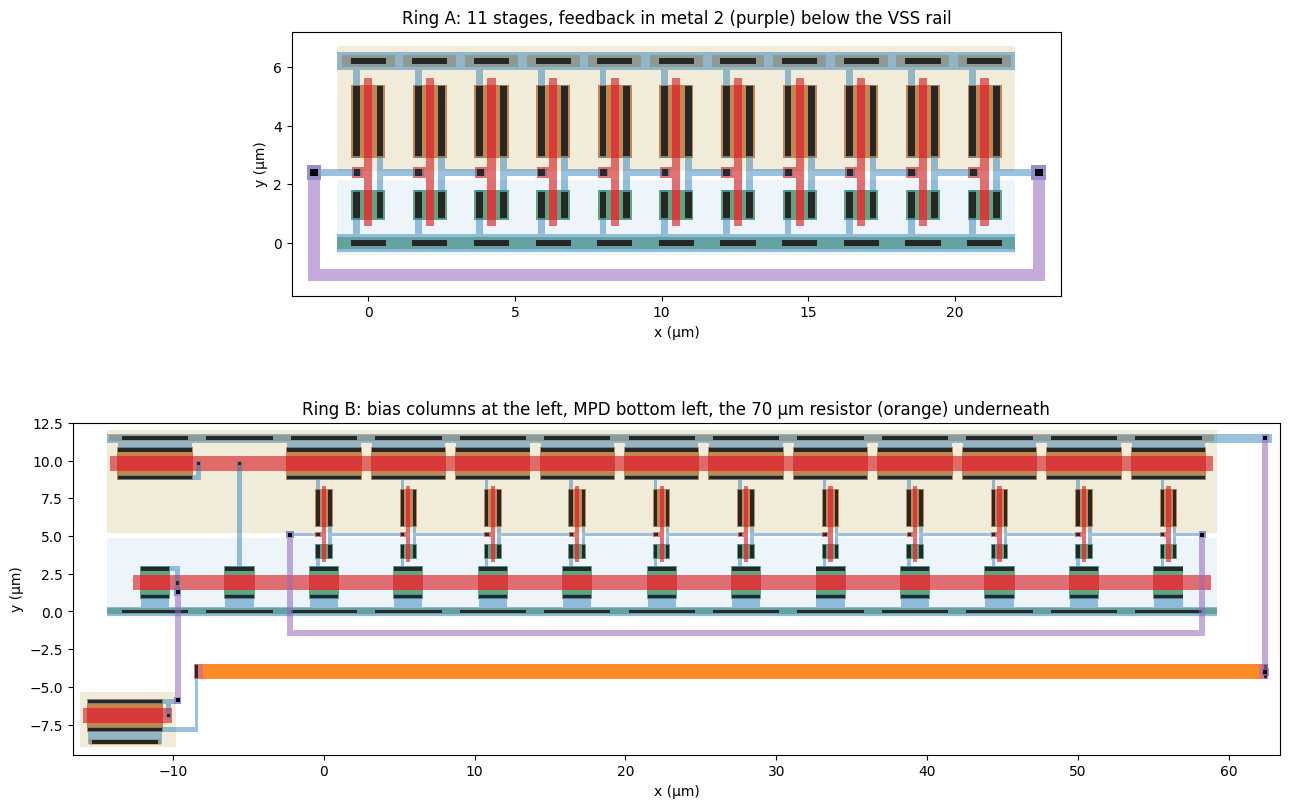

In [28]:
from matplotlib.patches import Rectangle

LAYER_STYLE = {   # magic layer: (colour, alpha, z-order)
    "nwell": ("#c9b26b", 0.25, 0), "pwell": ("#9fc5e8", 0.18, 0),
    "ndiff": ("#2e8b57", 0.75, 1), "pdiff": ("#b5651d", 0.75, 1), "psubdiff": ("#6aa84f", 0.6, 1),
    "nsubdiff": ("#e69138", 0.6, 1), "nmos": ("#d62728", 0.9, 2), "pmos": ("#d62728", 0.9, 2),
    "polysilicon": ("#d62728", 0.65, 2), "nhighres": ("#ff7f0e", 0.9, 2),
    "ndiffc": ("#111111", 0.9, 4), "pdiffc": ("#111111", 0.9, 4), "psubdiffcont": ("#111111", 0.9, 4),
    "nsubdiffcont": ("#111111", 0.9, 4), "polycontact": ("#111111", 0.9, 4),
    "metal1": ("#1f77b4", 0.45, 3), "metal2": ("#9467bd", 0.55, 5), "via1": ("#000000", 1.0, 6)}


def draw_mag(cell, ax):
    text = open(os.path.join(LAYOUT, f"{cell}.mag")).read()
    scale = 0.05 * np.divide(*map(int, re.search(r"magscale (\d+) (\d+)", text).groups()))
    for layer, body in re.findall(r"<< (\w+) >>\n((?:rect .*\n)*)", text):
        if layer not in LAYER_STYLE:
            continue
        c, a, z = LAYER_STYLE[layer]
        for line in body.splitlines():
            x1, y1, x2, y2 = (int(v) * scale for v in line.split()[1:5])
            ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, color=c, alpha=a, lw=0, zorder=z))
    x1, y1, x2, y2 = mag_bbox(cell)
    ax.set_xlim(x1 - 0.5, x2 + 0.5)
    ax.set_ylim(y1 - 0.5, y2 + 0.5)
    ax.set_aspect("equal")
    ax.set_xlabel("x (µm)")
    ax.set_ylabel("y (µm)")


fig, axes = plt.subplots(2, 1, figsize=(13, 9), gridspec_kw={"height_ratios": [1, 2.2]})
draw_mag("ring_a", axes[0])
axes[0].set_title("Ring A: 11 stages, feedback in metal 2 (purple) below the VSS rail")
draw_mag("ring_b", axes[1])
axes[1].set_title("Ring B: bias columns at the left, MPD bottom left, the 70 µm resistor (orange) underneath")
fig.tight_layout()
plt.show()

### 9.3 Post-layout simulation

The extracted netlists add what the schematics left out: the drain and source junction areas of every device and the
capacitance of the wiring. Each ring is simulated at the 13 points needed for its sensitivities and for the read-out
of 7.3 (−40, 25 and 125 °C at the three supplies, plus 0 and 50 °C and 3.2 and 3.4 V at 25 °C), 26 simulations.
The read-out is applied with the coefficients fitted on the schematic typical corner and a
fresh one-point calibration and supply trim on the post-layout rings.

In [29]:
def post_netlist(cell, vdd=3.3, corner="typical", temp=27, t_stop=30e-9, t_step=2e-12, rise_a=10, rise_b=30):
    h = vdd / 2
    res = f'.lib "{GF180_MODELS}/sm141064.spice" {RES_CORNER[corner]}\n' if cell == "ring_b" else ""
    return header(corner, temp) + res + textwrap.dedent(f'''\
        .include "{os.path.join(LAYOUT, cell + "_pex.spice")}"
        Vdd vdd 0 {vdd}
        X1 vdd 0 {cell}
        .ic v(x1.n0)=0 v(x1.n1)={vdd}
        .control
        tran {t_step} {t_stop} uic
        meas tran ta WHEN v(x1.n0)={h} RISE={rise_a}
        meas tran tb WHEN v(x1.n0)={h} RISE={rise_b}
        meas tran iavg AVG i(Vdd) FROM=ta TO=tb
        quit
        .endc
        .end
        ''')


POST_PTS = ([(t, v) for t in (-40, 25, 125) for v in VDDS] + [(0, 3.30), (50, 3.30), (25, 3.20), (25, 3.40)])


def post_point(job):
    ring, temp, vdd = job
    if ring == "A":
        r = run_ring(lambda **kw: post_netlist("ring_a", **kw), temp=temp, vdd=vdd, t_stop=60e-9, t_step=2e-12)
    else:
        r = run_ring(lambda **kw: post_netlist("ring_b", **kw), temp=temp, vdd=vdd, t_stop=1.2e-6, t_step=50e-12)
    return {"ring": ring, "temp_C": temp, "vdd_V": vdd, "f_Hz": r["f"], "power_W": r["power"]}


with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
    post = pd.DataFrame(list(ex.map(post_point, [(ring, t, v) for ring in ("A", "B") for t, v in POST_PTS])))


def post_sens(ring):
    d = post[post.ring == ring].set_index(["temp_C", "vdd_V"])
    f0 = d.f_Hz[(25, 3.30)]
    return (f0, d.power_W[(25, 3.30)], (d.f_Hz[(50, 3.30)] - d.f_Hz[(0, 3.30)]) / 50 / f0,
            (d.f_Hz[(25, 3.40)] - d.f_Hz[(25, 3.20)]) / 0.2 / f0)


sch_power = {r: pvt_[(pvt_.corner == "typical") & (pvt_.temp_C == 25) & np.isclose(pvt_.vdd_V, 3.30)].power_W.iloc[0]
             for r, pvt_ in (("A", pvt), ("B", pvt_b))}
rows = []
for ring, (f_s, tc_s, sv_s) in (("A", (fA, tA, vA)), ("B", sens_b[(B_BIAS, "typical")])):
    f_l, p_l, tc_l, sv_l = post_sens(ring)
    rows += [{"ring": ring, "netlist": "schematic", "f at 25 C (MHz)": f_s / 1e6, "P (uW)": 1e6 * sch_power[ring],
              "TC (%/C)": 100 * tc_s, "S_V (%/V)": 100 * sv_s},
             {"ring": ring, "netlist": "layout (extracted)", "f at 25 C (MHz)": f_l / 1e6, "P (uW)": 1e6 * p_l,
              "TC (%/C)": 100 * tc_l, "S_V (%/V)": 100 * sv_l}]
post_table = pd.DataFrame(rows).set_index(["ring", "netlist"]).round(3)
try:
    display(post_table)
except NameError:
    print(post_table.to_string())

# read-out of 7.3 on the post-layout rings: own calibration and supply trim, schematic coefficients
pl = (post.assign(vdd_V=post.vdd_V.round(2)).pivot_table(index=["temp_C", "vdd_V"], columns="ring", values="f_Hz")
      .reset_index())
pl = pl[pl.temp_C.isin(MC_TEMPS) & pl.vdd_V.isin(VDDS)].copy()
c25 = pl[(pl.temp_C == 25) & np.isclose(pl.vdd_V, 3.30)].iloc[0]
pl["xA"], pl["xB"] = np.log(pl.A / c25.A), np.log(pl.B / c25.B)
s25 = pl[pl.temp_C == 25].sort_values("vdd_V")
k_pl = (s25.xA.iloc[-1] - s25.xA.iloc[0]) / (s25.xB.iloc[-1] - s25.xB.iloc[0])
pl["eT_A"] = basis_a(pl.xA.to_numpy()) @ coef_a - pl.temp_C
pl["eT_trim"] = basis_trim((pl.xA - k_pl * pl.xB).to_numpy(), pl.xB.to_numpy()) @ coef_t - pl.temp_C
sch_pts = ref.assign(vdd_V=ref.vdd_V.round(2)).set_index(["temp_C", "vdd_V"])
readout_post = pd.DataFrame({
    "A alone, 3.3 V: schematic (C)": sch_pts.eT_A[sch_pts.index.get_level_values(1) == 3.30].abs().max(),
    "A alone, 3.3 V: layout (C)": pl.eT_A[np.isclose(pl.vdd_V, 3.30)].abs().max(),
    "A + B + trim: schematic (C)": sch_pts.eT_trim.abs().max(),
    "A + B + trim: layout (C)": pl.eT_trim.abs().max()}, index=["max |error|, -40 / 25 / 125 C"]).round(2)
try:
    display(readout_post)
except NameError:
    print(readout_post.to_string())

f at 25 C (MHz)    P (uW)  TC (%/C)  S_V (%/V)
ring netlist                                                           
A    schematic                  1200.854  1226.873    -0.189     22.248
     layout (extracted)          851.632  1236.702    -0.189     23.362
B    schematic                    46.857   183.562     0.071     20.244
     layout (extracted)           34.400   192.549     0.067     18.147

,"A alone, 3.3 V: schematic (C)","A alone, 3.3 V: layout (C)",A + B + trim: schematic (C),A + B + trim: layout (C)
"max |error|, -40 / 25 / 125 C",0.11,1.07,0.84,2.98


### 9.4 Interpretation

**The layout is clean and small.** Both rings pass magic's GF180 DRC with no errors and match their schematics in LVS
(22 and 49 devices). Ring A takes 25 × 8 µm (about 200 µm²) and ring B 79 × 21 µm (about 1660 µm²), most of it the
70 µm resistor and the 5 µm-wide pMOS starving devices: about 0.0019 mm² for the pair.

**Parasitics slow both rings by a common factor, and the calibration absorbs it.** The extracted netlists run 29 %
(ring A) and 27 % (ring B) slower than the schematics, mostly because of the drain and source junction capacitance,
which the schematic netlists left out (no junction areas), plus the wiring. A common slowdown is a multiplicative
factor, like most of the process variation in section 6, so the ratio calibration removes it: ring A's TC does not
move (−0.189 %/°C in both netlists), and ring A alone still reads temperature within about 1 °C at nominal supply with
the schematic coefficients.

**Ring B changes shape, not only speed.** Its TC falls 7 % (0.071 to 0.067 %/°C) and its supply sensitivity 10 %:
the added capacitance, part of it voltage-dependent junction capacitance, changes how ring B's delay depends on its
current and on the swing. The supply trim measures the new $S_V$ on each chip, but the TC change is the same kind of
error as the mismatch of 7.5, so the two-ring read-out with schematic coefficients errs by up to 3.0 °C instead of
0.8 °C. The read-out of a real chip therefore has to be fitted on extracted netlists, and finally on measured chips.

## 10. Comparison with published work

| Work | Technology | Principle | Data | Range (°C) | Calibration | Inaccuracy | Supply sensitivity | Power / energy |
|---|---|---|---|---|---|---|---|---|
| This work | GF180MCU 180 nm, 3.3 V | Two 11-stage rings (plain and resistor-biased current-starved), frequency ratios | Schematic simulation (5 corners, 16-chip mismatch Monte Carlo); DRC/LVS-clean layout, extracted at typical | −40 to 125 | 1 temperature (25 °C) + 2 extra supply points | Corners: ≤ 4.9 °C (ff), ≤ 2 °C in the other four, over ±10 % supply. Mismatch adds ±8.0 °C (3σ), ±2.4 °C with the larger mirror reference (7.8) or the correction of 7.6 | ≤ 3.5 °C/V (A + B); 126–166 °C/V for ring A alone (worst over temperature, cell below) | 1.4 mW continuous (A: 1.22 mW at 1.2 GHz, B: 0.18 mW); counter not modelled; 0.0019 mm² (layout) |
| [Anand 2016] | 65 nm, 1.0 V | Two rings with different $L$ ($\Delta V_{TH}$ from reverse short-channel effect), frequency ratio | Measured | 0 to 100 | 1 point / 2 points | ±3.3 °C / ±0.9 °C (2nd-order correction) | 34 °C/V (0.034 °C/mV) | 154 µW; ≈1 pJ/conversion at 1 °C quantization; 0.004 mm² |
| [Yang 2017] | 180 nm, 1.2 V | Subthreshold ring, exponential temperature dependence | Measured | −20 to 80 (fully integrated, RC reference) | 2 points + one universal correction | ±0.76 °C (3σ, 5 chips) | 0.36 °C/V | 4.56 nJ/conversion (0.6 nJ sensing core); 8865 µm² |
| [Chen 2010] | 65 nm, 0.3 to 1 V | Weak-inversion current into a ring for T, a ZTC ring for process, voltage-to-time for supply | Simulation | −50 to 125 | Not described | ±0.8 °C over 0.3 to 1 V supply | Not reported | 3.7 µW at 0.3 V, 10 kS/s |

Notes on reading the table:

- **The inaccuracy figures are not directly comparable.** This work reports worst-case process corners and a
  mismatch Monte Carlo separately, in simulation; [Anand 2016] and [Yang 2017] report measured errors over a few
  chips, which include both, and [Chen 2010] is also a simulation.
- **Supply sensitivity per 1 % of supply** puts different supply voltages on the same footing: about 0.11 °C for this
  work (3.3 °C/V × 33 mV, cell below), 0.34 °C for [Anand 2016] (34 °C/V × 10 mV) and 0.004 °C for [Yang 2017]
  (0.36 °C/V × 12 mV), whose subthreshold ring runs behind a supply-regulating native NMOS header.
- [Anand 2016] also uses two rings with different temperature sensitivities, made to differ through $V_{TH}$ (channel
  length), and digitizes their frequency ratio, which needs no reference clock. This work makes the rings differ
  through what sets their current (device drive versus a resistor bias), which gives them opposite temperature
  coefficients, and combines them with per-chip supply slopes instead of a plain ratio.
- For aging, [Kim 2007] compares a stressed ring with an unstressed reference ring through their beat frequency,
  the same three-observable idea discussed in section 8.4.

In [30]:
# residual supply sensitivity of each read-out: change of the temperature reading between 2.97 V and 3.63 V,
# per volt, at every corner and temperature (no new simulations: uses the read-out of section 7.3)
def per_volt(err_col):
    d = m.assign(reading=m[err_col] + m.temp_C).sort_values("vdd_V")
    return d.groupby(["corner", "temp_C"]).reading.apply(lambda r: (r.iloc[-1] - r.iloc[0]) / 0.66).abs()


supply_sens = pd.DataFrame({"ring A alone (C/V)": per_volt("eT_A").groupby("corner").max(),
                            "A + B + supply trim (C/V)": per_volt("eT_trim").groupby("corner").max()})
supply_sens = supply_sens.reindex(CORNERS).round(2)
supply_sens.index.name = "worst over temperature"
try:
    display(supply_sens)
except NameError:
    print(supply_sens.to_string())

,ring A alone (C/V),A + B + supply trim (C/V)
worst over temperature,,
typical,146.75,2.00
ff,125.79,1.53
ss,166.33,3.31
fs,149.98,2.05
sf,144.01,1.84


### 10.1 Interpretation

**Supply rejection: in between, and by computation rather than regulation.** Per 1 % of supply, this work moves
about 0.11 °C, three times better than [Anand 2016] (0.34 °C) and far from [Yang 2017] (0.004 °C). The difference with
[Yang 2017] is one of kind: its native NMOS header physically keeps supply changes from reaching the ring, at a cost
in voltage headroom, power and area. The supply trim here does not stop $V_{DD}$ from changing the frequency; ring B
estimates $V_{DD}$ and the read-out subtracts its effect. That correction is only as good as ring B, which is why the
aging of ring B (section 8) degrades it while a regulator's rejection would not depend on it.

**Inaccuracy: the gap follows the number of calibration temperatures.** With one calibration point [Anand 2016]
reaches ±3.3 °C, comparable to this work's ≤ 4.9 °C in the worst corner; with two points it reaches ±0.9 °C, and
[Yang 2017] reaches ±0.76 °C, also with two points. The figures are not one-to-one: the corners are worst-case, which
is pessimistic, while measured chips also include the mismatch that the Monte Carlo of 7.5 adds (±8 °C, 3σ). That
spread is ring B's TC, exactly what a second calibration temperature measures, which explains most of the gap to the
two-point designs; a second temperature is expensive in production, though. The calibration-frequency correction of
7.6 recovers much of it (±2.4 °C) without one, once a model trained on Monte Carlo data can separate process from
mismatch.

**Power: the rings run fast and all the time.** Ring A uses about 1.02 pJ per cycle at 1.2 GHz, so
$P = E_{cycle} \cdot f$ gives 1.22 mW. Two levers cut the average power: power the rings only during a conversion
(for example 10 µs every 10 ms, a 0.1 % duty cycle, about 1.4 µW on average, which also reduces aging stress), and
lower the frequency with more stages or more load. The limit is the counter: counting for a window $T_w$ quantizes
the frequency to $1/(f\,T_w)$, so the slower ring B, at 47 MHz, sets how long each conversion must last.

## 11. Limitations

- **Statistical variation (partial).** The mismatch Monte Carlo has 16 chips, so its 3σ figures carry about ±20 %
  uncertainty, and it runs on the typical corner only: global statistical variation, and mismatch combined with the
  other corners, are not simulated. The correction of 7.6 is validated across chips (leave-one-out) but only within the
  typical corner, and the larger mirror reference of 7.8 is verified on the typical corner only, without layout. The
  single resistor has no mismatch partner; its process spread is covered by the `res_*` corners.
- **Mixed corners.** Resistor process corners are included (`res_ss`, `res_ff`, ±20 % sheet resistance) but always
  paired with the matching MOS corner; combinations such as ss MOS with `res_ff` are not covered.
- **Layout (partial).** The layout passes magic's GF180 DRC deck; the KLayout sign-off deck of the PDK (which needs a
  Ruby-enabled KLayout), antenna and density checks were not run. Extraction gives capacitance but no wire
  resistance, at the typical corner only: the PVT grids, the Monte Carlo and the aging study use the schematic
  netlists, and the read-out was not refitted on the extracted ones. There is no pad frame or output buffer.
- **Aging (partial).** Only the inverter devices are aged (section 8). The DC stress on ring B's stack, mirror and
  starving devices, and recovery effects of BTI, are not modelled.
- **Numerical precision.** With a 2 ps time step the simulated frequency converges to a few hundred ppm, about
  ±0.3 °C (section 11.1). Runs on different machines differed by up to about 0.2 °C, within that precision, so errors
  are reported with one decimal.
- **Implementation.** The frequency read-out itself (a counter, its resolution and conversion time, and the accuracy
  of its reference clock) is not modelled.

### 11.1 Numerical accuracy

Three ring-A points simulated with the default 2 ps step and with a 0.5 ps step; the frequency change is converted
to an equivalent temperature with TC ≈ 0.18 %/°C.

In [31]:
acc_pts = [("typical", 25, 3.30), ("ss", -40, 2.97), ("typical", 125, 2.97)]


def accuracy(p):
    corner, temp, vdd = p
    f_default = run_ro(corner=corner, temp=temp, vdd=vdd)["f"]
    f_fine = run_ro(corner=corner, temp=temp, vdd=vdd, t_step=0.5e-12)["f"]
    ppm = (f_fine / f_default - 1) * 1e6
    return {"corner": corner, "temp_C": temp, "vdd_V": vdd, "f default (GHz)": f_default / 1e9,
            "change with 0.5 ps (ppm)": ppm, "equivalent (C)": abs(ppm) * 1e-6 / 0.0018}


with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
    acc = pd.DataFrame(list(ex.map(accuracy, acc_pts))).round(3)
try:
    display(acc)
except NameError:
    print(acc.to_string())

,corner,temp_C,vdd_V,f default (GHz),change with 0.5 ps (ppm),equivalent (C)
0,typical,25,3.30,1.201,238.306,0.132
1,ss,-40,2.97,1.024,177.964,0.099
2,typical,125,2.97,0.933,561.704,0.312


## 12. Error budget

Every error source quantified in this notebook, for ring A alone and for the two-ring read-out with the supply
trim, in °C over −40 to 125 °C: worst case for the systematic sources, 3σ for mismatch, and per 10 mV of
$\Delta V_{TH}$ for aging. No new simulations.

,kind,ring A alone (C),A + B + supply trim (C)
source,,,
Process corners with a ±10 % supply (worst corner),systematic,62.92,4.90
"Mismatch, 16 chips (3σ)",random,0.33,8.02
Mismatch with the calibration-frequency correction (7.6),random,NaN,2.36
"Mismatch with MNB, MNM at 8/4 (7.8)",random,NaN,2.40
"Layout parasitics, schematic coefficients (9.3)",systematic,1.07,2.98
"Aging, 10 mV of NBTI (8.3)",drift,1.00,3.12
Numerical precision (11.1),simulation,0.31,0.31


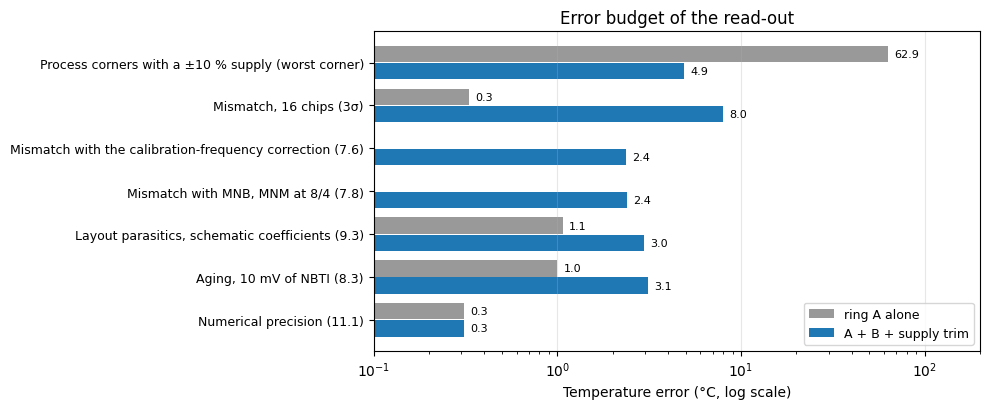

In [32]:
cf_row = "   + calibration-frequency correction"
budget = pd.DataFrame([
    ("Process corners with a ±10 % supply (worst corner)", "systematic",
     readout["1) A alone, 3.3 V +/-10 % (C)"].max(), readout["3) A + B + supply trim (C)"].max()),
    ("Mismatch, 16 chips (3σ)", "random",
     mc_table.loc["A alone, 3.3 V", "MC: max 3 sigma (C)"],
     mc_table.loc["A + B + supply trim, 3.3 V +/-10 %", "MC: max 3 sigma (C)"]),
    ("Mismatch with the calibration-frequency correction (7.6)", "random", np.nan,
     corr_table.loc[cf_row, "MC: max 3 sigma (C)"]),
    ("Mismatch with MNB, MNM at 8/4 (7.8)", "random", np.nan, fix_table.loc["MNB, MNM 8/4 (fix)", "max 3 sigma (C)"]),
    ("Layout parasitics, schematic coefficients (9.3)", "systematic",
     readout_post["A alone, 3.3 V: layout (C)"].iloc[0], readout_post["A + B + trim: layout (C)"].iloc[0]),
    ("Aging, 10 mV of NBTI (8.3)", "drift",
     abs(equiv.loc["NBTI (pMOS)", "A alone: apparent dT (C)"]), abs(equiv.loc["NBTI (pMOS)", "A + B: apparent dT (C)"])),
    ("Numerical precision (11.1)", "simulation", acc["equivalent (C)"].max(), acc["equivalent (C)"].max()),
], columns=["source", "kind", "ring A alone (C)", "A + B + supply trim (C)"]).set_index("source")
try:
    display(budget.round(2))
except NameError:
    print(budget.round(2).to_string())

fig, ax = plt.subplots(figsize=(10, 4.2))
y = np.arange(len(budget))[::-1]
for dy, col, color in ((0.2, "ring A alone (C)", "0.6"), (-0.2, "A + B + supply trim (C)", "#1f77b4")):
    vals = budget[col].to_numpy(dtype=float)
    ok = ~np.isnan(vals)
    ax.barh(y[ok] + dy, vals[ok], height=0.38, color=color, label=col.replace(" (C)", ""))
    for yy, v in zip(y[ok] + dy, vals[ok]):
        ax.text(v * 1.08, yy, f"{v:.1f}", va="center", fontsize=8)
ax.set_xscale("log")
ax.set_xlim(0.1, 200)
ax.set_yticks(y)
ax.set_yticklabels(budget.index, fontsize=9)
ax.set_xlabel("Temperature error (°C, log scale)")
ax.set_title("Error budget of the read-out")
ax.grid(axis="x", alpha=0.3)
ax.legend(fontsize=9, loc="lower right")
fig.tight_layout()
plt.show()

**Ring A alone has one problem, the supply:** 63 °C over a ±10 % supply in the worst corner, against about 1 °C or
less from every other source. **The two-ring read-out trades it for several smaller errors of similar size:** the
corner residual (4.9 °C, systematic), mismatch (8.0 °C, 3σ, or 2.4 °C with either fix), layout parasitics (3.0 °C,
until the read-out is refitted on extracted netlists) and aging (3.1 °C per 10 mV). The two systematic terms disappear
with a fit on the right data (extracted netlists first, measured chips last); the random term has a verified fix
(7.8); aging is the one without a remedy in this design, which makes the unstressed reference ring of section 8 the
most important next step.

## 13. Conclusions

- **One ring cannot tell temperature from supply.** Process mostly scales the current, so a one-point calibration
  and the ratio $\ln(f/f_{25})$ remove it: ring A's TC varies only ±1 % across corners, and a shared quadratic reads
  temperature within about 1.5 °C at nominal supply. The supply is the real limit, at 1.1–1.4 °C per 10 mV, or about
  ±41 °C for a ±10 % regulator.
- **Two rings work when they differ in what sets their current.** Ring A's current comes from device drive, ring B's
  from a resistor, which gives them opposite temperature coefficients. The bias stack under the resistor decides the
  rest: one diode leaves the pair almost collinear (condition number 33), two diodes separate it (1.7), and a pMOS
  over an nMOS diode keeps the separation (2.1) while cancelling the fs/sf corners. With one calibration temperature
  and a supply trim, the read-out stays within about 2 °C in four corners and 5 °C in ff.
- **Mismatch sets the real accuracy, and it sits in one device.** A 16-chip Monte Carlo leaves ring A nearly untouched
  (±0.3 °C, 3σ) but spreads the two-ring read-out by ±8 °C, because the mirror reference MNB, shared by every stage of
  ring B, changes both its current and its TC. Making MNB and MNM 16 times larger brings it to ±2.4 °C (verified by a
  second Monte Carlo, typical corner); a second calibration temperature or a correction from ring B's own calibration
  frequency (±2.4 °C, leave-one-out) are the alternatives, the last one without hardware cost but only once process
  and mismatch can be told apart.
- **Layout costs speed, not the principle.** Both rings are DRC- and LVS-clean in about 0.0019 mm². Parasitics slow
  them by 27–29 %, which the ratio calibration absorbs for ring A (unchanged TC), but they lower ring B's TC by 7 %, so
  the two-ring read-out has to be fitted on extracted netlists.
- **Aging is the price of ring B.** The two rings age in opposite directions, and two measurements cannot separate
  three unknowns, so 10 mV of NBTI reads as about 3 °C instead of 1 °C for ring A alone. The two-ring read-out still
  wins up to roughly 170 mV of NBTI, but aging dominates its error beyond about 15 mV. A third ring that sees the same
  temperature and supply but stays unstressed would turn aging from a hidden error into a measurement.
- **Against published sensors**, the supply rejection is three times better per percent of supply than a measured
  two-ring design with a frequency ratio. Once mismatch is included, the accuracy is behind one-point-calibrated
  designs unless the calibration-frequency correction is used, and the gap to the best measured sensors follows their
  second calibration temperature, which measures exactly the TC spread found here.

## 14. Future work

- **Process-aware calibration.** Run a Monte Carlo with global variation and mismatch together (`sw_stat_global=1`)
  and train a read-out model on the absolute calibration frequencies of both rings, so that it can tell process from
  mismatch; section 7.6 shows the information is there. This targets both the ff/ss residual and the mismatch spread
  without a second calibration temperature, and is the natural link to machine-learning-based PVT and aging
  prediction.
- **Reference ring for aging**, powered only during conversions, plus aging of ring B's stack and mirror devices.
- **Sizing study**: repeat the corners and the layout for the larger mirror reference of 7.8, and explore how $N$,
  $W_p/W_n$, $L$ and $R$ change the sensitivities and the energy per conversion.
- **Read-out and power**: a frequency counter with its conversion time, and duty-cycled operation of both rings.
- **Toward tape-out**: KLayout sign-off DRC, the read-out refitted on extracted netlists (with wire resistance and
  corners), a pad frame with output buffers, and a slot on an open GF180MCU shuttle.

## References

- GF180MCU primitive device library (`gf180mcu_fd_pr`), Apache 2.0:
  https://github.com/fossi-foundation/globalfoundries-pdk-libs-gf180mcu_fd_pr
- ngspice: https://ngspice.sourceforge.io/
- magic VLSI layout tool: http://opencircuitdesign.com/magic/
- netgen LVS: http://opencircuitdesign.com/netgen/
- open_pdks (GF180MCU technology files for magic and netgen): https://github.com/RTimothyEdwards/open_pdks
- litex-hub conda packages of the open-source EDA tools: https://anaconda.org/litex-hub
- schemdraw: https://schemdraw.readthedocs.io/
- [Anand 2016] T. Anand, K. A. A. Makinwa and P. K. Hanumolu, "A VCO based highly digital temperature sensor with
  0.034 °C/mV supply sensitivity," *IEEE J. Solid-State Circuits*, vol. 51, no. 11, p. 2651, Nov. 2016.
  https://web.engr.oregonstate.edu/~anandt/papers/anand_jssc_2016.pdf
- [Yang 2017] K. Yang, Q. Dong, W. Jung, Y. Zhang, M. Choi, D. Blaauw and D. Sylvester, "A 0.6nJ −0.22/+0.19°C
  inaccuracy temperature sensor using exponential subthreshold oscillation dependence," *ISSCC*, paper 9.2, 2017.
  https://blaauw.engin.umich.edu/wp-content/uploads/sites/342/2018/02/Kaiyuan-Yang-A-0.6nJ-0.220.19C-Inaccuracy-Temperature-Sensor-Using.pdf
- [Chen 2010] S.-W. Chen, M.-H. Chang, W.-C. Hsieh and W. Hwang, "Fully on-chip temperature, process, and voltage
  sensors," *Proc. IEEE ISCAS*, pp. 897–900, 2010. https://ieeexplore.ieee.org/document/5537410
- [Kim 2007] T.-H. Kim, R. Persaud and C. H. Kim, "Silicon odometer: an on-chip reliability monitor for measuring
  frequency degradation of digital circuits," *Symp. VLSI Circuits*, pp. 122–123, 2007.
  https://doi.org/10.1109/VLSIC.2007.4342682